# Radar Cidadão — Módulo de Visão Computacional
## Detecção de lixo e entulho em via pública (YOLO + transfer learning)

**Radar Cidadão:** cidadãos registram problemas da cidade, sensores confirmam os riscos e a população recebe alertas para se proteger de alagamentos.

Este módulo detecta **resíduos e entulho em via pública** nas fotos enviadas pelos cidadãos e nas imagens de câmeras. Lixo acumulado entope bueiros e agrava alagamentos, então ele alimenta direto o carro-chefe do app. A saída é a imagem com caixas delimitadoras, a **confiança** de cada detecção e um pacote JSON de triagem para o protótipo CitizenTech.

> **Importante:** a detecção automática apoia a triagem e a priorização de rotas de inspeção. Ela **não substitui a vistoria técnica presencial**.

### Como rodar
1. No Colab: **Ambiente de execução → Alterar tipo de ambiente → GPU (T4)**.
2. Rode as células em ordem (**Ambiente de execução → Executar tudo**). O treino leva cerca de 30 a 60 min na T4.
3. Ao final, a célula de exportação gera `radar_cidadao_resultados.zip`, com métricas, gráficos, latência e FPS para o relatório técnico.

### Roteiro (etapas do enunciado)
| Etapa | Seções |
|---|---|
| 1. Selecionar e preparar os dados | 1 a 4 |
| 2. Implementar a solução | 5 |
| 3. Avaliar a qualidade | 6 a 8 |
| 4. Demonstrar a integração | 9 e 10 |
| 5. Medir desempenho e justificar | 11 e 12 |

## 0. Instalação e verificação do hardware

In [1]:
!pip -q install ultralytics gradio

import os, io, re, json, time, glob, random, shutil, subprocess, platform
from collections import defaultdict
import numpy as np, pandas as pd, cv2, torch, requests
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from concurrent.futures import ThreadPoolExecutor
from IPython.display import display, Image as IPImage
import ultralytics
from ultralytics import YOLO

print('Python', platform.python_version(), '| torch', torch.__version__, '| ultralytics', ultralytics.__version__)
print('GPU disponível:', torch.cuda.is_available(), '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'sem GPU')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Python 3.13.16 | torch 2.14.1+cu130 | ultralytics 8.4.215
GPU disponível: True | Tesla T4


## 1. Configuração

- `FONTE_DADOS = 'taco'`: usa a base pública **TACO (Trash Annotations in Context)**, com cerca de 1.500 fotos de resíduos em ambientes reais (ruas, calçadas, parques) e caixas delimitadoras no formato COCO.
- `FONTE_DADOS = 'proprio'`: usa uma amostra rotulada pelo grupo (por exemplo, fotos de ruas de São Paulo anotadas no Roboflow ou no CVAT). Envie um `.zip` no **formato YOLO**, com as pastas `images/` e `labels/`.
- `NEGATIVOS_ZIP` (opcional, recomendado): um `.zip` com fotos de ruas **limpas**. Elas entram como imagens sem rótulo, ensinam o modelo a não disparar falso alarme e permitem medir a matriz de confusão por imagem.

In [2]:
SEED = 42
FONTE_DADOS = 'taco'                       # 'taco' ou 'proprio'
CAMINHO_PROPRIO = '/content/meu_dataset.zip'
NEGATIVOS_ZIP = '/content/negativos.zip'   # opcional; ignorado se não existir

BASE = '/content/radar'
MAX_LADO = 1024          # imagens salvas com no máximo 1024 px no maior lado (economiza disco e I/O)
MODELO_BASE = 'yolo11n.pt'   # YOLO11 nano pré-treinado no COCO (transfer learning)
EPOCAS, IMGSZ, BATCH = 60, 640, 16
TREINAR_COMPARACAO = False   # True = treina também o yolo11s para comparar qualidade x velocidade

CLASSE = 'residuo'
CLASSE_PT = 'Resíduo/entulho em via pública'

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
os.makedirs(BASE, exist_ok=True)
RES = f'{BASE}/resultados'; os.makedirs(RES, exist_ok=True)

## 2. Obtenção dos dados

Na TACO, baixamos a versão de 640 px de cada foto (mais leve). Se ela não existir, usamos a original. As anotações da TACO estão na orientação **já corrigida pelo EXIF**, então cada foto é rotacionada conforme o EXIF e conferida contra a largura e a altura anotadas. Fotos cuja proporção não bate são descartadas e contadas, em vez de gerar caixas desalinhadas.

Todas as categorias da TACO (garrafa, sacola, papelão etc.) são unidas numa classe única, `residuo`. Para a triagem municipal, o que importa é **onde há resíduo**, não o tipo de embalagem.

In [3]:
RAW = f'{BASE}/raw'; os.makedirs(RAW, exist_ok=True)
amostras = []   # lista de dicts: {'img': caminho, 'labels': [linhas YOLO], 'negativo': bool}

if FONTE_DADOS == 'taco':
    if not os.path.exists('/content/TACO'):
        !git clone -q https://github.com/pedropro/TACO.git /content/TACO
    ann = json.load(open('/content/TACO/data/annotations.json'))
    print('TACO:', len(ann['images']), 'imagens |', len(ann['annotations']), 'anotações |', len(ann['categories']), 'categorias')

    anns_por_img = defaultdict(list)
    for a in ann['annotations']:
        anns_por_img[a['image_id']].append(a)

    def proporcao_ok(img, W, H):
        return abs(img.size[0] / img.size[1] - W / H) < 0.02

    def baixar(im):
        destino = f"{RAW}/{im['id']}.jpg"
        if os.path.exists(destino):
            return im['id'], 'ok'
        for chave in ('flickr_640_url', 'flickr_url'):
            url = im.get(chave)
            if not url:
                continue
            try:
                r = requests.get(url, timeout=30); r.raise_for_status()
                bruta = Image.open(io.BytesIO(r.content))
                img = ImageOps.exif_transpose(bruta)        # anotações seguem a orientação corrigida
                if not proporcao_ok(img, im['width'], im['height']):
                    img = bruta
                    if not proporcao_ok(img, im['width'], im['height']):
                        return im['id'], 'orientacao'
                img = img.convert('RGB'); img.thumbnail((MAX_LADO, MAX_LADO))
                img.save(destino, quality=92)               # salvo sem EXIF: pixels = orientação das anotações
                return im['id'], 'ok'
            except Exception:
                continue
        return im['id'], 'falha'

    with ThreadPoolExecutor(16) as ex:
        status = dict(ex.map(baixar, ann['images']))
    print(pd.Series(status).value_counts().to_string())

    def linhas_yolo(im):
        W, H = im['width'], im['height']; linhas = []
        for a in anns_por_img[im['id']]:
            x, y, w, h = a['bbox']
            if w < 2 or h < 2:
                continue
            cx, cy = np.clip((x + w / 2) / W, 0, 1), np.clip((y + h / 2) / H, 0, 1)
            linhas.append(f'0 {cx:.6f} {cy:.6f} {min(w / W, 1):.6f} {min(h / H, 1):.6f}')
        return linhas

    for im in ann['images']:
        if status.get(im['id']) == 'ok':
            amostras.append({'img': f"{RAW}/{im['id']}.jpg", 'labels': linhas_yolo(im), 'negativo': False})

else:  # dataset próprio em formato YOLO
    !rm -rf /content/proprio && mkdir -p /content/proprio && unzip -q "$CAMINHO_PROPRIO" -d /content/proprio
    imgs = [p for p in glob.glob('/content/proprio/**/images/**/*.*', recursive=True)
            if p.lower().endswith(('.jpg', '.jpeg', '.png'))]
    for p in imgs:
        lab = re.sub(r'/images/', '/labels/', p); lab = os.path.splitext(lab)[0] + '.txt'
        linhas = []
        if os.path.exists(lab):   # todas as classes viram 'residuo' (classe 0)
            linhas = ['0 ' + ' '.join(l.split()[1:5]) for l in open(lab) if len(l.split()) >= 5]
        destino = f'{RAW}/{len(amostras)}.jpg'
        im = ImageOps.exif_transpose(Image.open(p)).convert('RGB'); im.thumbnail((MAX_LADO, MAX_LADO)); im.save(destino, quality=92)
        amostras.append({'img': destino, 'labels': linhas, 'negativo': len(linhas) == 0})

# Negativos opcionais (ruas limpas, sem rótulo)
if os.path.exists(NEGATIVOS_ZIP):
    !rm -rf /content/neg && mkdir -p /content/neg && unzip -q "$NEGATIVOS_ZIP" -d /content/neg
    for k, p in enumerate(glob.glob('/content/neg/**/*.*', recursive=True)):
        if p.lower().endswith(('.jpg', '.jpeg', '.png')):
            destino = f'{RAW}/neg_{k}.jpg'
            im = ImageOps.exif_transpose(Image.open(p)).convert('RGB'); im.thumbnail((MAX_LADO, MAX_LADO)); im.save(destino, quality=92)
            amostras.append({'img': destino, 'labels': [], 'negativo': True})

print('Amostras utilizáveis:', len(amostras), '| positivas:', sum(not a['negativo'] for a in amostras),
      '| negativas:', sum(a['negativo'] for a in amostras))

TACO: 1500 imagens | 4784 anotações | 60 categorias
ok    1500
Amostras utilizáveis: 1500 | positivas: 1500 | negativas: 0


## 3. Exploração das imagens e dos rótulos

Verificamos a quantidade de objetos por imagem e o **tamanho relativo das caixas**. Objetos pequenos (menos de 1% da área da imagem) são a principal dificuldade da TACO e influenciam a escolha de resolução.

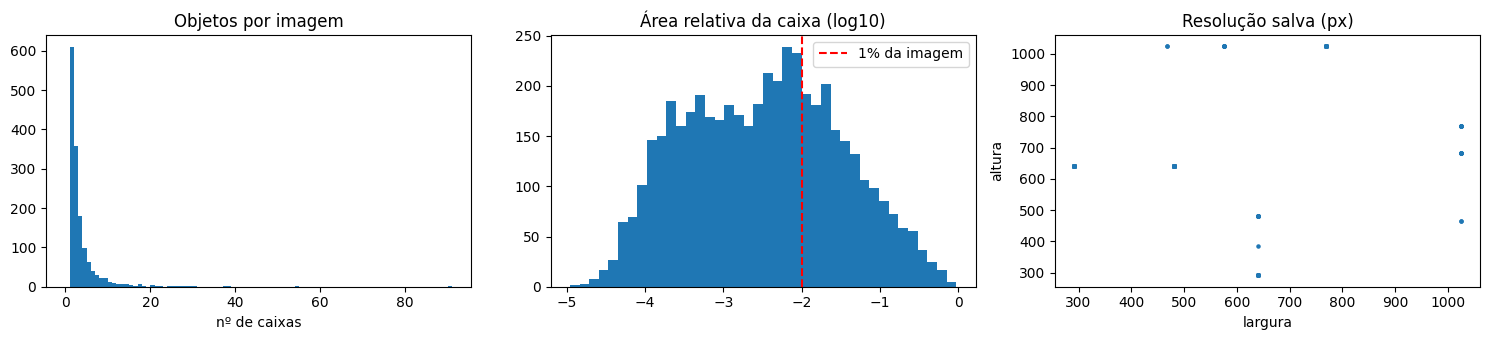

Total de caixas: 4784 | caixas pequenas (<1% da imagem): 67.2%


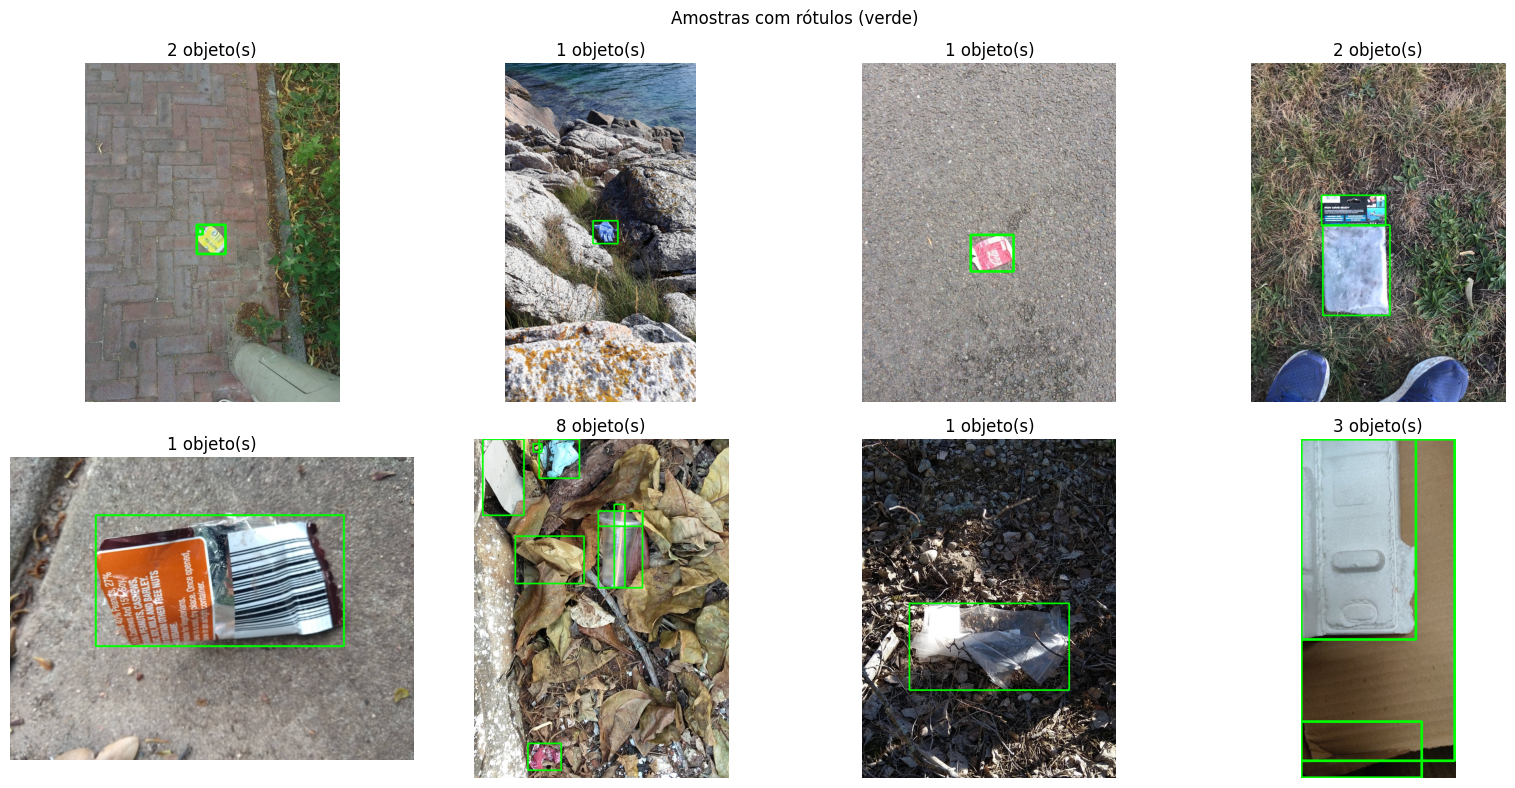

In [4]:
n_caixas = [len(a['labels']) for a in amostras if not a['negativo']]
areas = [float(l.split()[3]) * float(l.split()[4]) for a in amostras for l in a['labels']]
dims = [Image.open(a['img']).size for a in amostras[:300]]

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].hist(n_caixas, bins=range(0, max(n_caixas) + 2)); ax[0].set_title('Objetos por imagem'); ax[0].set_xlabel('nº de caixas')
ax[1].hist(np.log10(np.array(areas) + 1e-6), bins=40); ax[1].set_title('Área relativa da caixa (log10)'); ax[1].axvline(-2, color='r', ls='--', label='1% da imagem'); ax[1].legend()
ax[2].scatter([d[0] for d in dims], [d[1] for d in dims], s=5); ax[2].set_title('Resolução salva (px)'); ax[2].set_xlabel('largura'); ax[2].set_ylabel('altura')
plt.tight_layout(); plt.savefig(f'{RES}/exploracao.png', dpi=120); plt.show()
print(f'Total de caixas: {len(areas)} | caixas pequenas (<1% da imagem): {np.mean(np.array(areas) < 0.01):.1%}')

def desenhar_gt(caminho, linhas, cor=(0, 255, 0)):
    img = cv2.imread(caminho); H, W = img.shape[:2]
    for l in linhas:
        _, cx, cy, w, h = map(float, l.split())
        x1, y1, x2, y2 = int((cx - w / 2) * W), int((cy - h / 2) * H), int((cx + w / 2) * W), int((cy + h / 2) * H)
        cv2.rectangle(img, (x1, y1), (x2, y2), cor, 3)
    return img[..., ::-1]

fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for a, s in zip(ax.flat, random.sample([x for x in amostras if not x['negativo']], 8)):
    a.imshow(desenhar_gt(s['img'], s['labels'])); a.set_title(f"{len(s['labels'])} objeto(s)"); a.axis('off')
plt.suptitle('Amostras com rótulos (verde)'); plt.tight_layout(); plt.savefig(f'{RES}/amostras_rotulos.png', dpi=100); plt.show()

## 4. Divisão treino / validação / teste sem vazamento

O enunciado pede para **não espalhar recortes ou variações da mesma imagem original** entre conjuntos diferentes. Fazemos isso em três camadas:

1. **Divisão por imagem original**, antes de qualquer aumento de dados.
2. **Agrupamento de quase-duplicatas:** um *hash* perceptual (dHash de 64 bits) identifica fotos quase idênticas, como duas fotos seguidas do mesmo lixo. Fotos com distância de Hamming ≤ 6 formam um grupo, e **cada grupo vai inteiro para um único conjunto**.
3. **Aumento de dados só no treino e em tempo real** (mosaico, brilho, espelhamento), feito pelo Ultralytics durante o treinamento. Nenhuma variação aumentada é gravada em disco nem chega à validação ou ao teste.

Proporção: 70% treino, 15% validação, 15% teste.

**Pré-processamento:** redimensionamento para no máximo 1024 px no disco (seção 2). No treino e na inferência, o YOLO aplica *letterbox* para 640×640 (mantém a proporção e completa com bordas) e **normaliza os pixels para [0, 1]** (divisão por 255), conversão BGR→RGB e formato CHW.

In [5]:
def dhash(caminho, n=8):
    g = np.asarray(Image.open(caminho).convert('L').resize((n + 1, n)), dtype=np.int16)
    return (g[:, 1:] > g[:, :-1]).flatten()

H = np.array([dhash(a['img']) for a in amostras])
dist = (H[:, None, :] != H[None, :, :]).sum(-1)

pai = list(range(len(amostras)))
def raiz(i):
    while pai[i] != i:
        pai[i] = pai[pai[i]]; i = pai[i]
    return i
for i, j in zip(*np.where(np.triu(dist <= 6, k=1))):
    pai[raiz(i)] = raiz(j)
grupos = defaultdict(list)
for i in range(len(amostras)):
    grupos[raiz(i)].append(i)
print(f'{len(amostras)} imagens em {len(grupos)} grupos | grupos com quase-duplicatas: {sum(len(g) > 1 for g in grupos.values())}')

ids_grupos = list(grupos.keys()); random.Random(SEED).shuffle(ids_grupos)
split_de = {}; total = len(amostras); acum = 0
for g in ids_grupos:
    destino = 'train' if acum < 0.70 * total else ('val' if acum < 0.85 * total else 'test')
    for i in grupos[g]:
        split_de[i] = destino
    acum += len(grupos[g])

# Verificação: nenhum grupo atravessa conjuntos
assert all(len({split_de[i] for i in g}) == 1 for g in grupos.values()), 'vazamento entre conjuntos!'

YOLO_DIR = f'{BASE}/yolo'
shutil.rmtree(YOLO_DIR, ignore_errors=True)
for s in ('train', 'val', 'test'):
    os.makedirs(f'{YOLO_DIR}/images/{s}'); os.makedirs(f'{YOLO_DIR}/labels/{s}')
for i, a in enumerate(amostras):
    s = split_de[i]; nome = os.path.basename(a['img'])
    shutil.copy(a['img'], f'{YOLO_DIR}/images/{s}/{nome}')
    with open(f"{YOLO_DIR}/labels/{s}/{os.path.splitext(nome)[0]}.txt", 'w') as f:
        f.write('\n'.join(a['labels']))

DATA_YAML = f'{YOLO_DIR}/data.yaml'
with open(DATA_YAML, 'w') as f:
    f.write(f"path: {YOLO_DIR}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n  0: {CLASSE}\n")

tab_split = pd.DataFrame([{'conjunto': s,
    'imagens': sum(v == s for v in split_de.values()),
    'negativas': sum(split_de[i] == s and a['negativo'] for i, a in enumerate(amostras)),
    'caixas': sum(len(a['labels']) for i, a in enumerate(amostras) if split_de[i] == s)} for s in ('train', 'val', 'test')])
tab_split.to_csv(f'{RES}/divisao_conjuntos.csv', index=False); display(tab_split)

1500 imagens em 1489 grupos | grupos com quase-duplicatas: 7


,conjunto,imagens,negativas,caixas
0,train,1050,0,3086
1,val,225,0,723
2,test,225,0,975


## 5. Implementação: YOLO11n com transfer learning

**Por que detecção (caixas), e não só classificação?** A equipe da prefeitura precisa saber **onde** está o resíduo e **quanto** da imagem ele ocupa (um saco isolado ou um ponto de descarte com entulho). Isso ajuda a priorizar.

**Por que YOLO11n?**
- É um detector de **um estágio**: localiza e classifica numa única passada, o que permite o monitoramento contínuo de vídeo.
- Tem cerca de **2,6 milhões de parâmetros** e roda em tempo real até em CPU, o que viabiliza processamento perto da câmera ou num servidor municipal modesto.
- Vem **pré-treinado no COCO**, então já reconhece bordas, texturas e objetos comuns (garrafas, sacolas). O *fine-tuning* só especializa essas camadas para "resíduo em via pública", o que funciona bem com poucas imagens.
- Alternativas consideradas: SSD (geralmente menos preciso com objetos pequenos) e YOLO11s (mais preciso, porém mais lento; dá para comparar com `TREINAR_COMPARACAO = True`).

**Ajustes de aumento de dados escolhidos para o ambiente urbano:** `hsv_v=0.5` (variação forte de brilho, para sombras e contraluz), `degrees=5` (fotos de celular tortas) e `fliplr=0.5`. O mosaico, padrão do YOLO, combina 4 imagens e ajuda com objetos pequenos e parcialmente cortados.

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/radar/yolo/data.yaml, degrees=5, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.5, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_residuo, nbs=64, nms=None, opset=None, optimize=False,

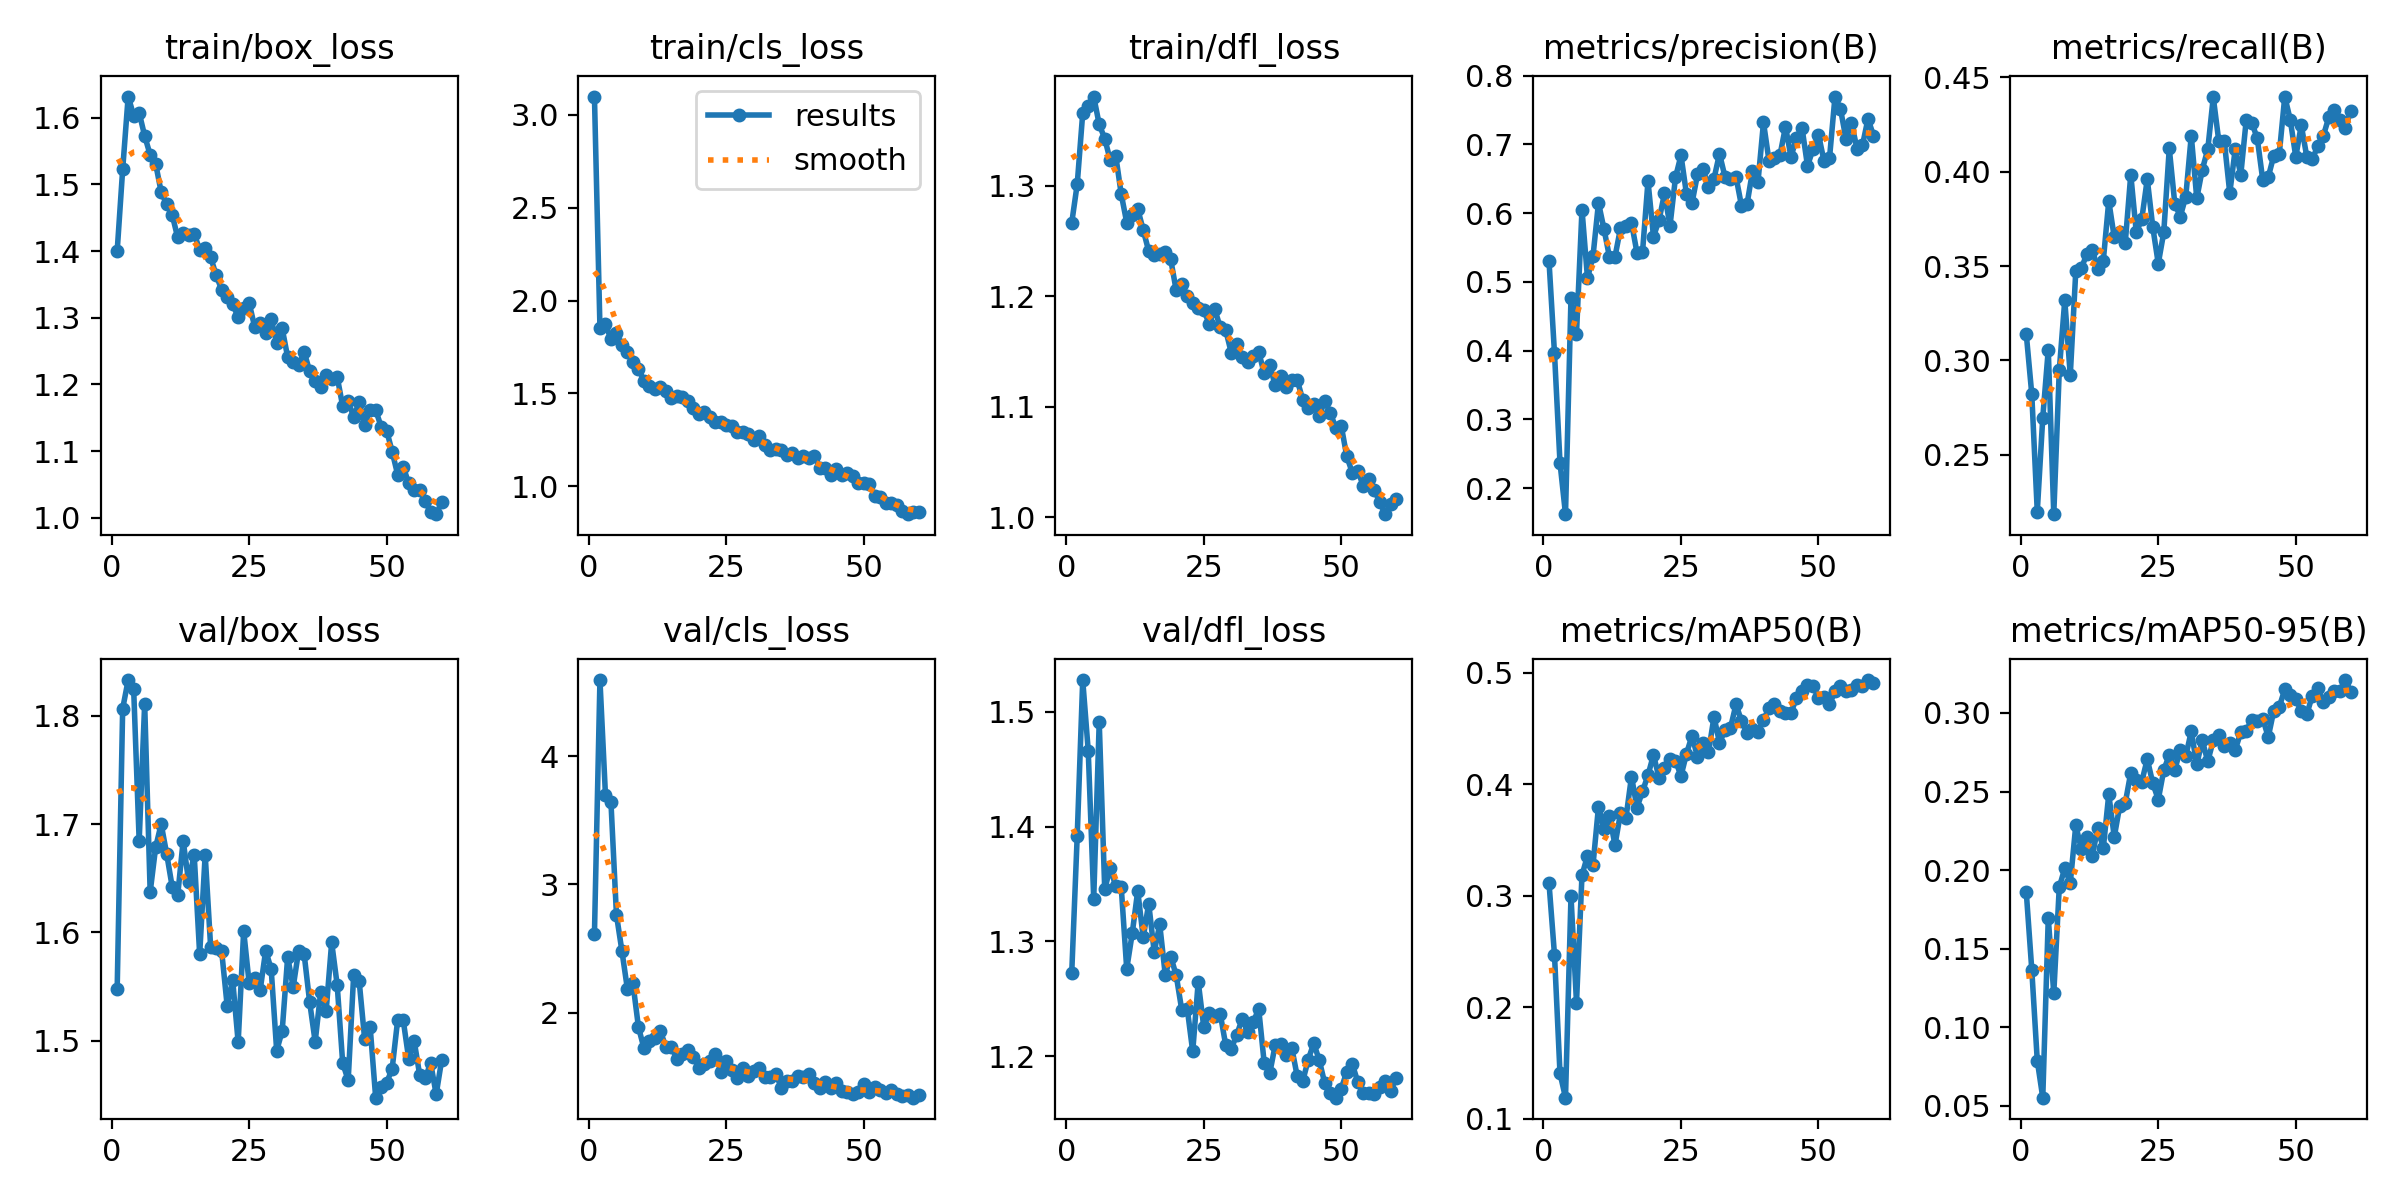

In [7]:
def treinar(pesos_base, nome):
    m = YOLO(pesos_base)
    m.train(data=DATA_YAML, epochs=EPOCAS, imgsz=IMGSZ, batch=BATCH, patience=15, seed=SEED, deterministic=True,
            hsv_v=0.5, degrees=5, fliplr=0.5, project=f'{BASE}/runs', name=nome, exist_ok=True, plots=True, verbose=False)
    return f'{BASE}/runs/{nome}/weights/best.pt'

PESOS = treinar(MODELO_BASE, 'yolo11n_residuo')
PESOS_COMP = treinar('yolo11s.pt', 'yolo11s_residuo') if TREINAR_COMPARACAO else None
melhor = YOLO(PESOS)
print('Pesos finais:', PESOS)

# Curvas de treino (perda e mAP por época)
for f in glob.glob(f'{BASE}/runs/yolo11n_residuo/results.png'):
    display(IPImage(f, width=900)); shutil.copy(f, f'{RES}/curvas_treino.png')

## 6. Avaliação no conjunto de teste: precisão, recall, F1 e mAP

O conjunto de teste **não foi usado** no treino nem na escolha do melhor modelo (que usa a validação). Métricas de detecção:
- **Precisão:** das caixas previstas, quantas são resíduo de verdade.
- **Recall:** dos resíduos reais, quantos o modelo encontrou.
- **mAP@0,5:** área sob a curva precisão × recall com IoU ≥ 0,5. **mAP@0,5:0,95:** média em IoUs de 0,5 a 0,95 (mais exigente com o ajuste da caixa).
- **Matriz de confusão** (gerada pelo Ultralytics), com a linha e a coluna de "fundo" (background): falsos positivos e resíduos não detectados.

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1767.2±747.5 MB/s, size: 229.6 KB)
val: Scanning /content/radar/yolo/labels/test... 225 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 225/225 1.7Kit/s 0.1s
val: New cache created: /content/radar/yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 4.6it/s 3.2s
                   all        225        975      0.604      0.367        0.4      0.254
Speed: 1.6ms preprocess, 3.8ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to /content/radar/runs/teste


,precisao,recall,f1,mAP50,mAP50_95
0,0.604,0.367,0.457,0.4,0.254


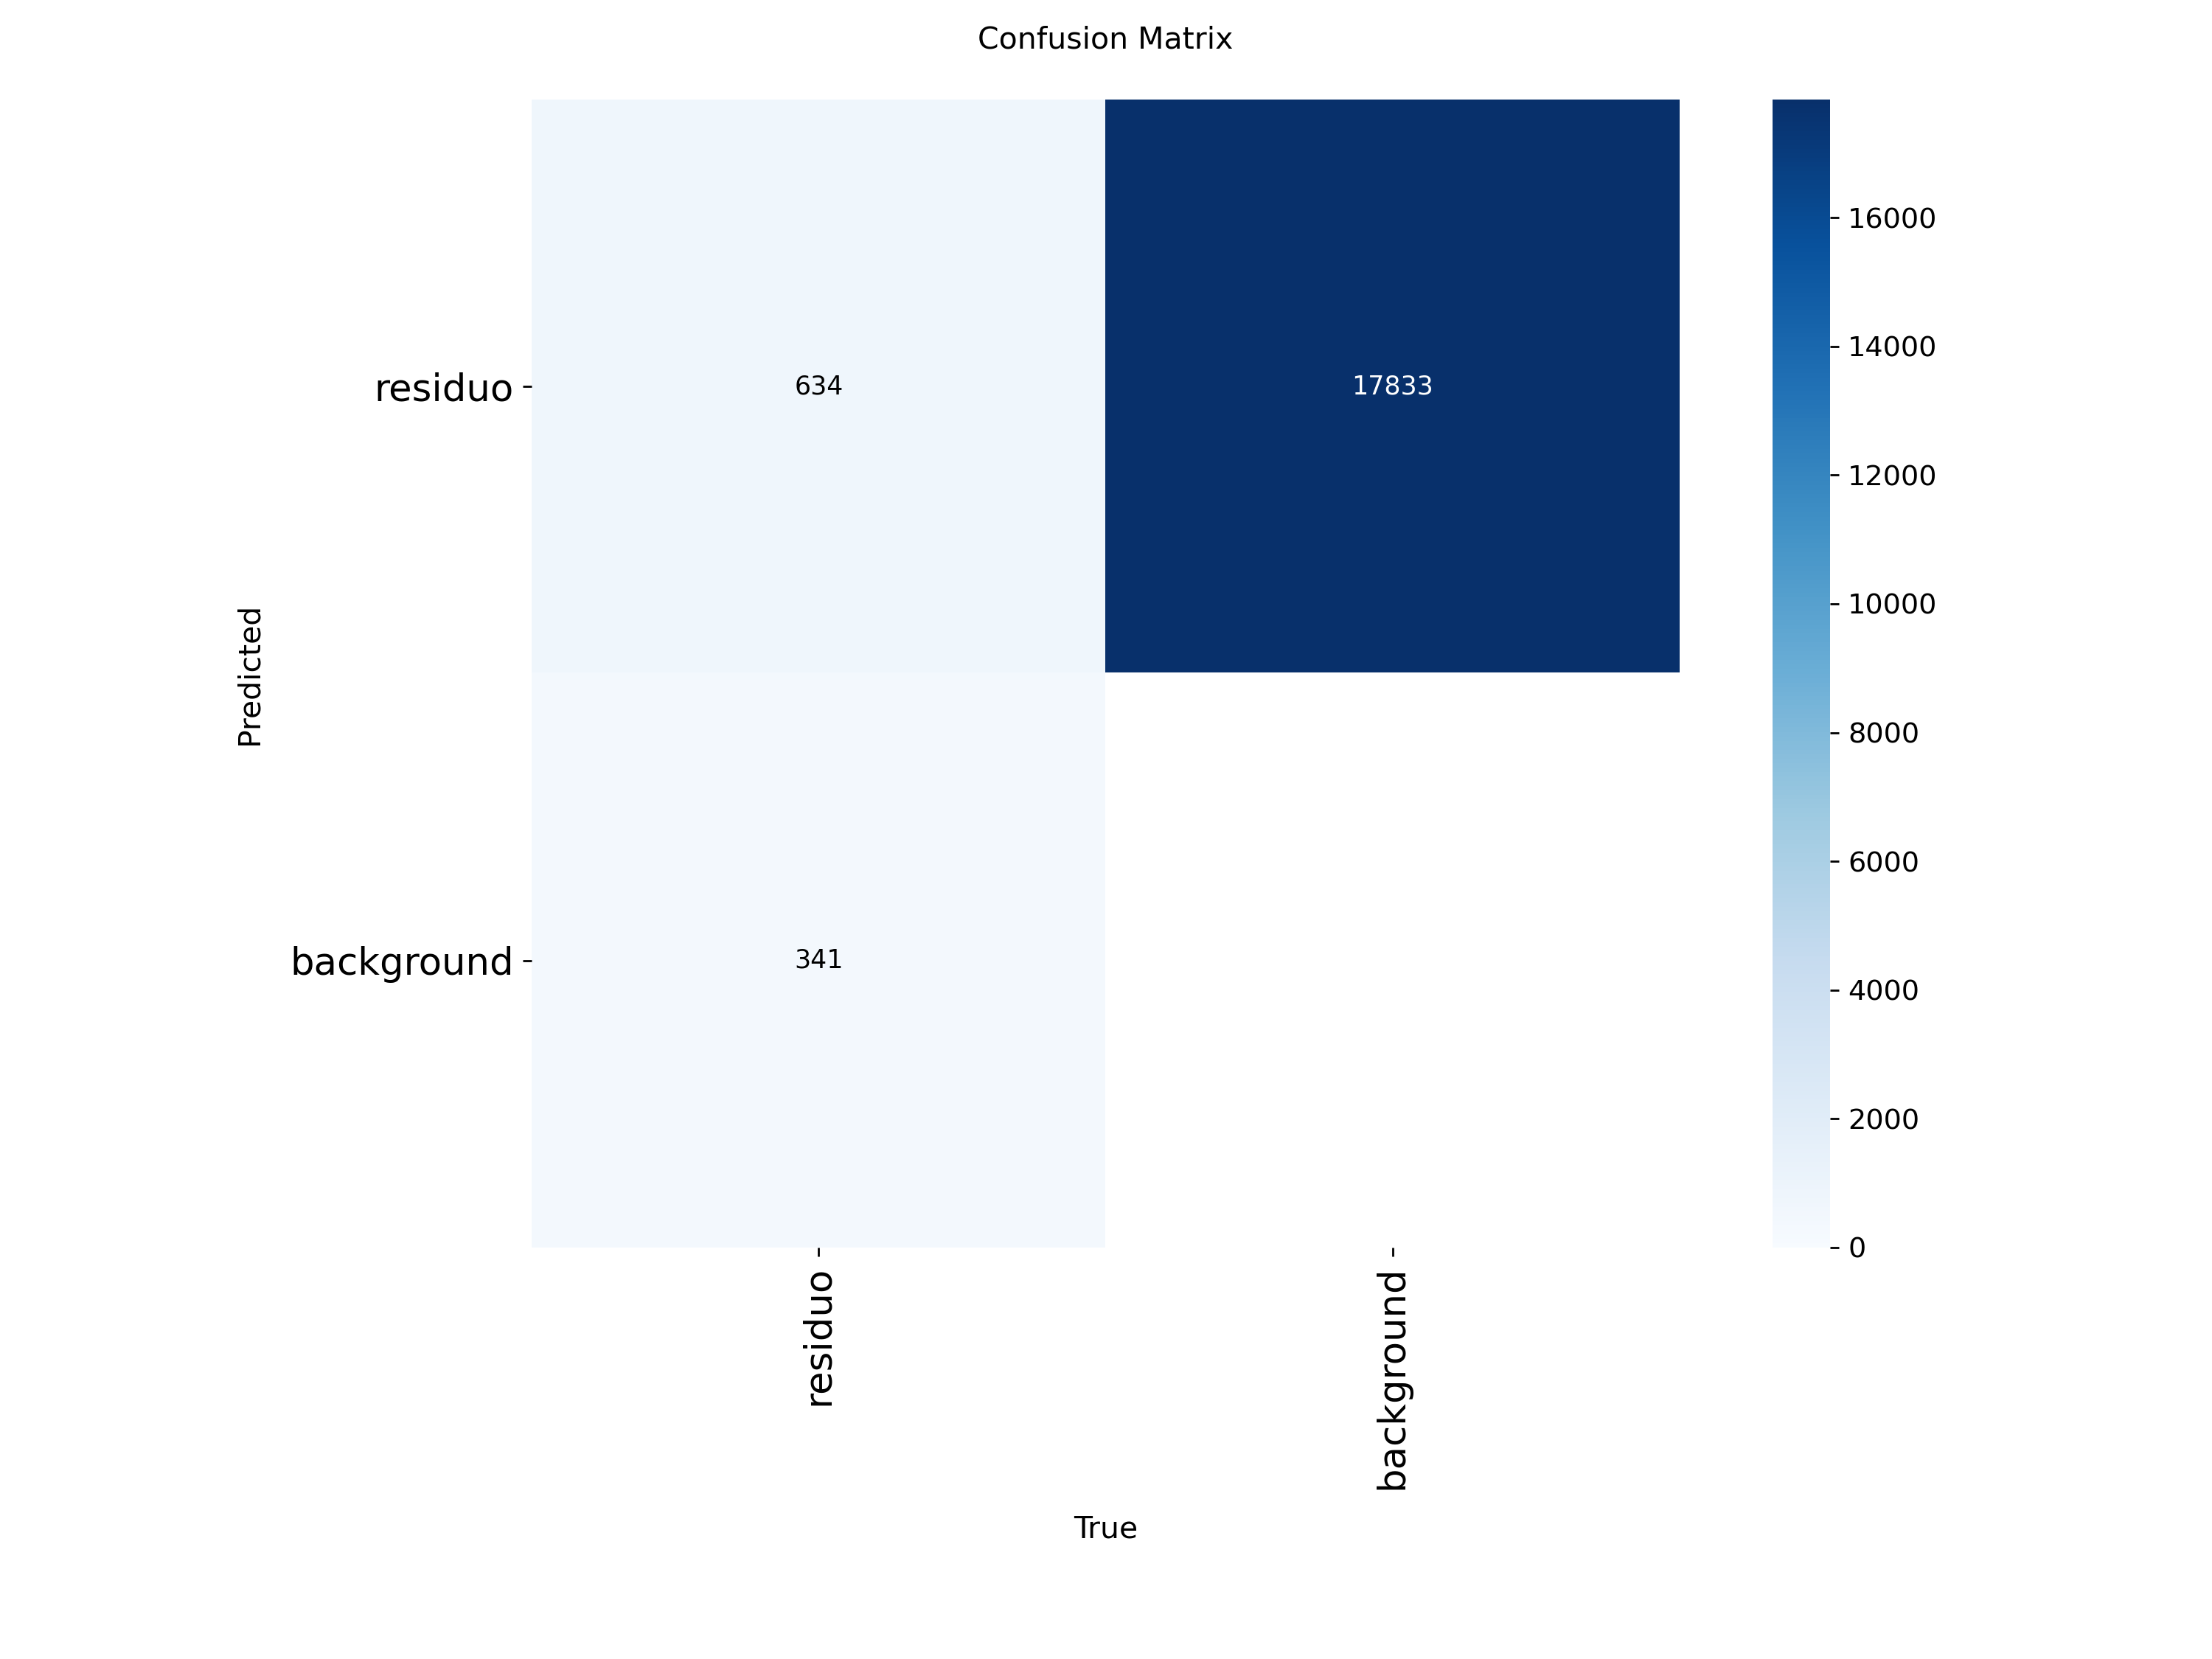

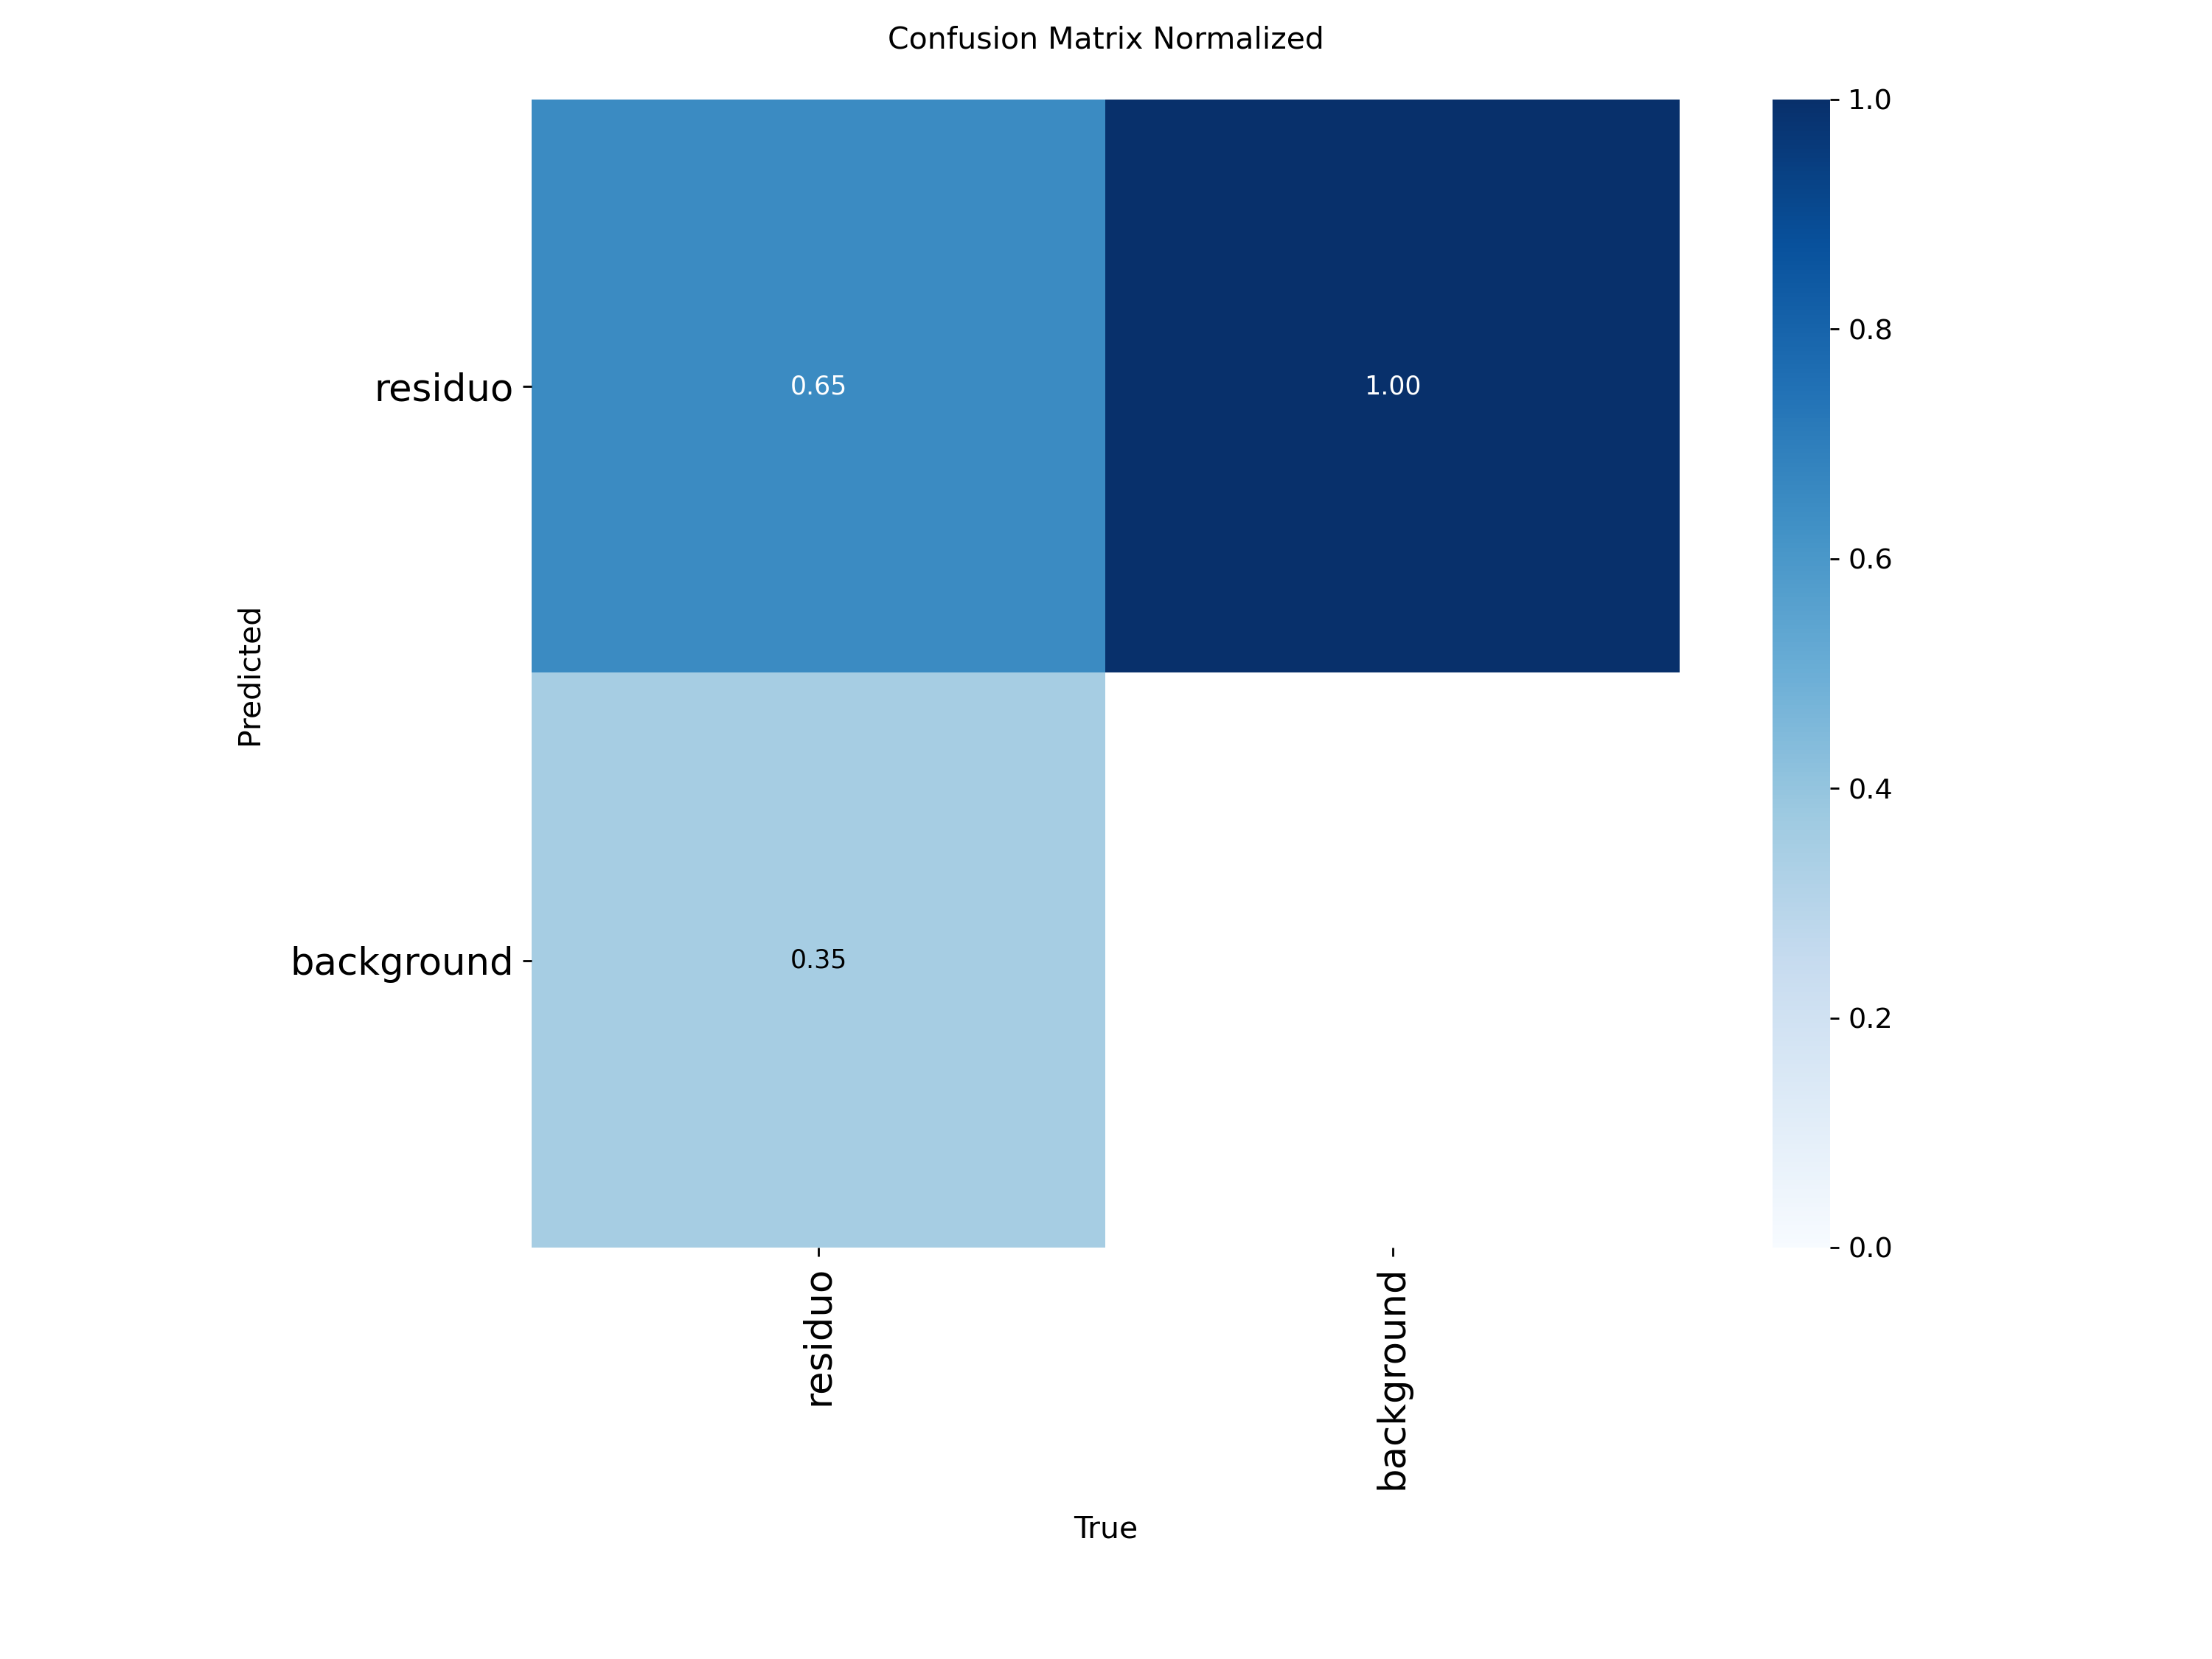

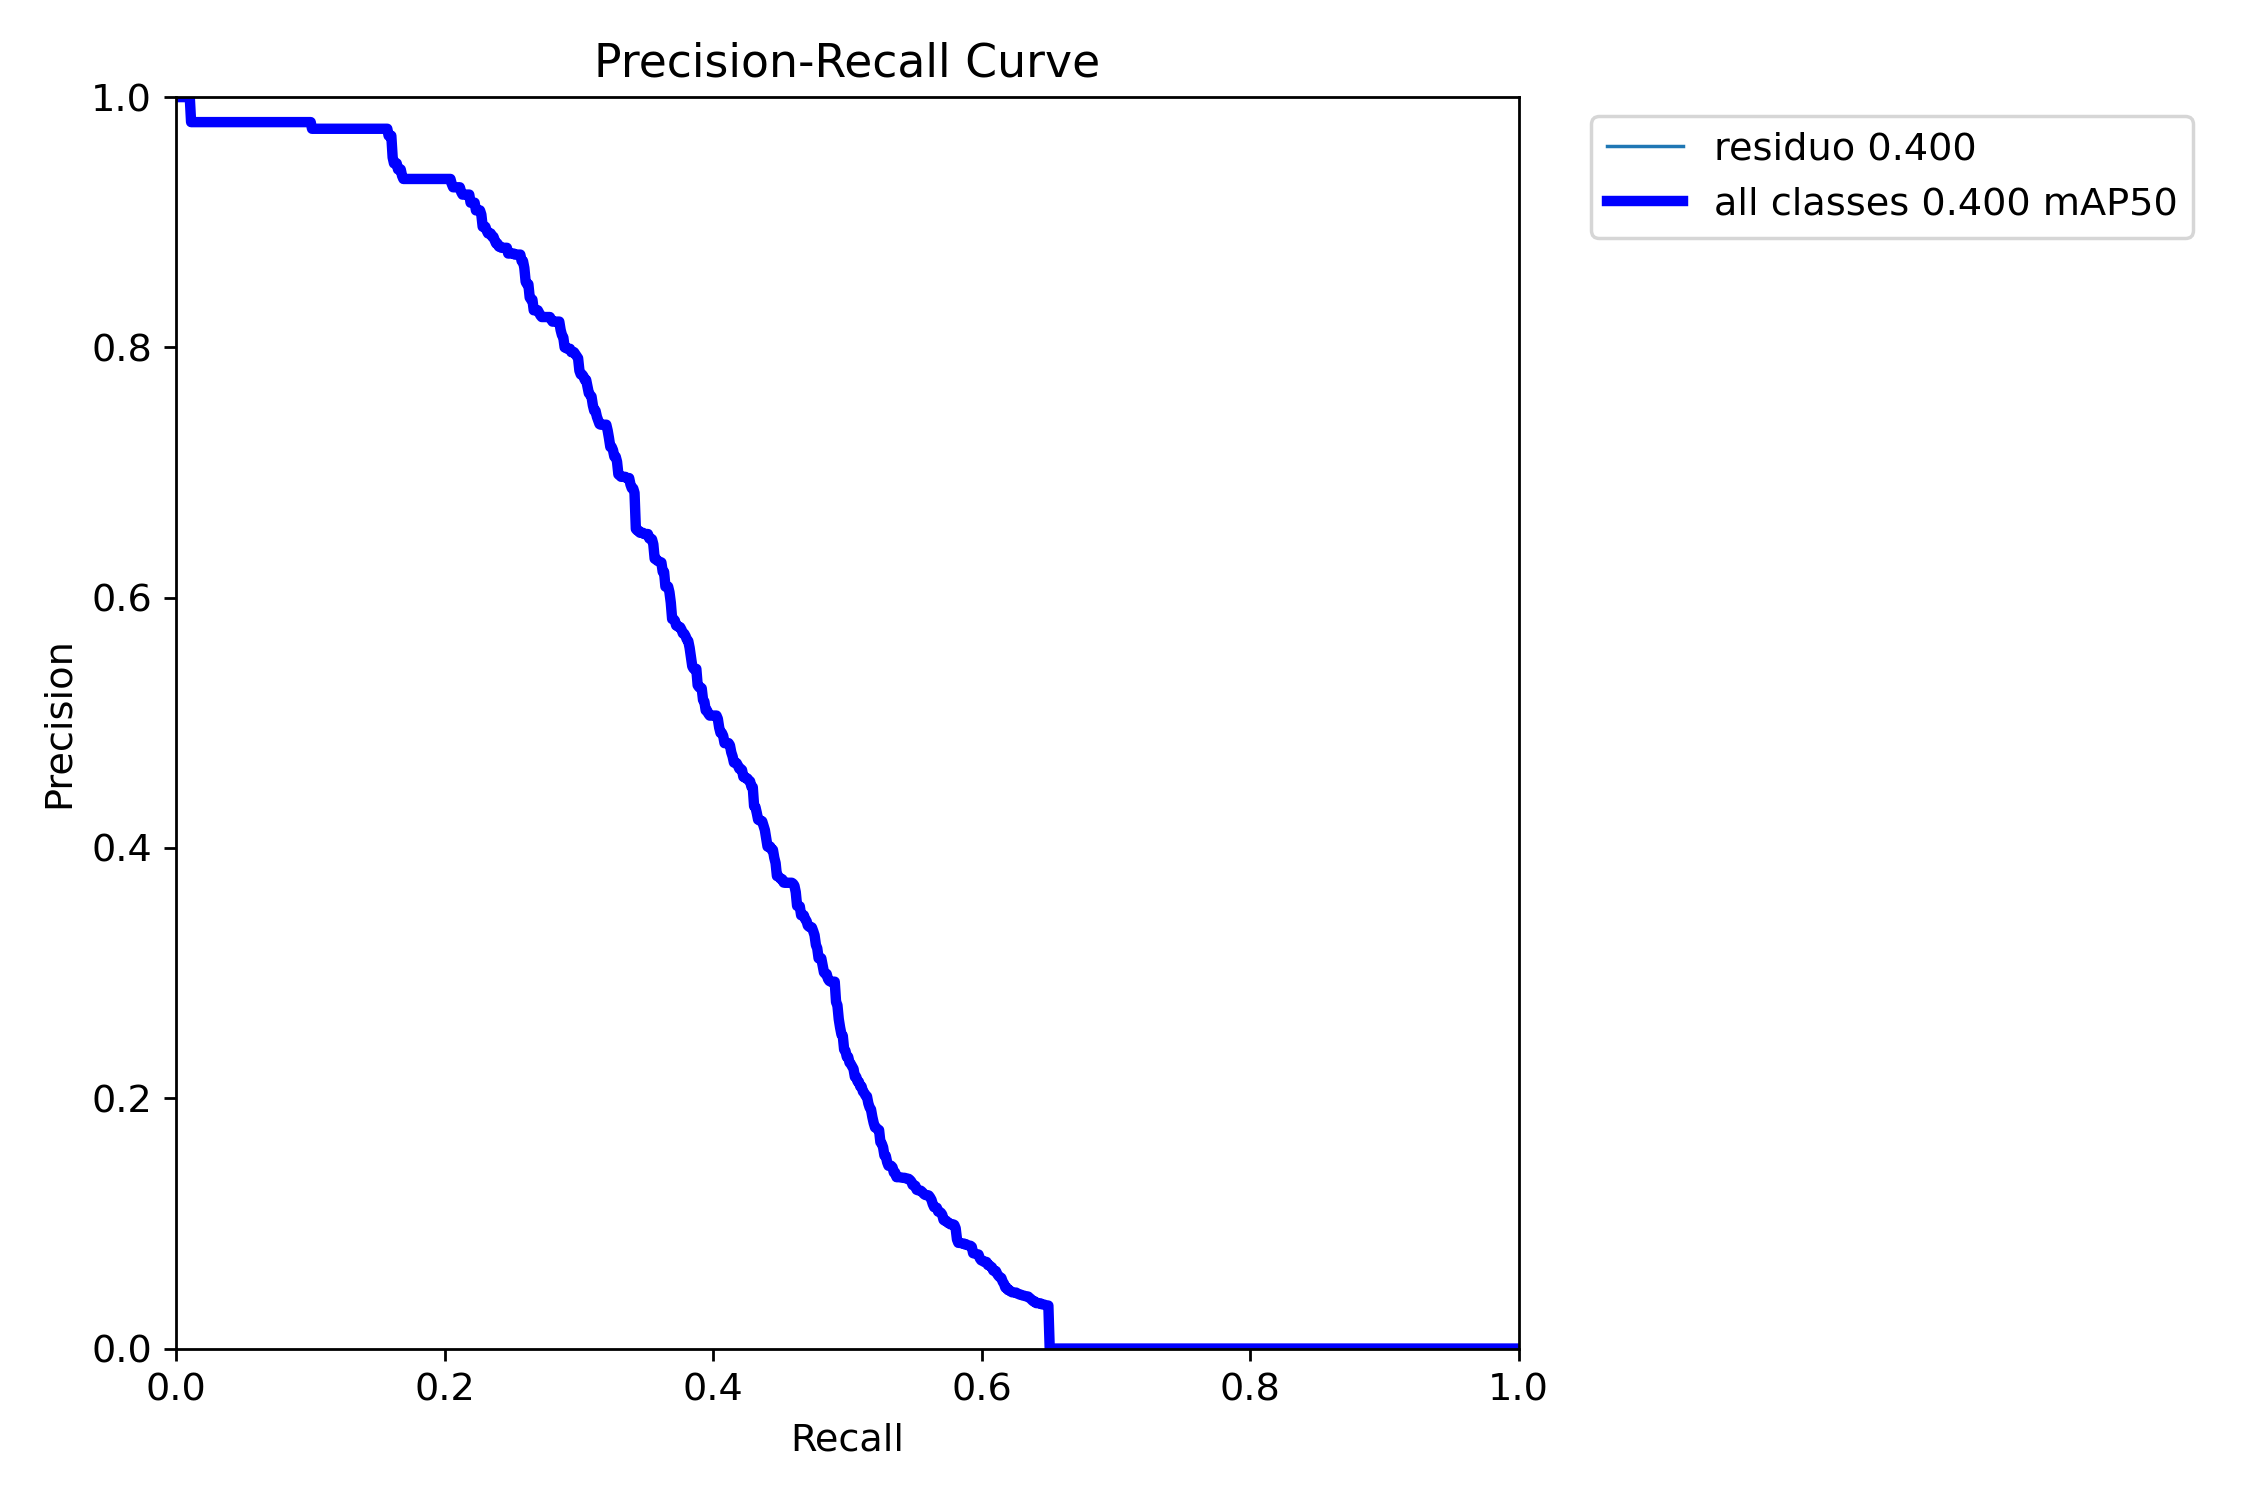

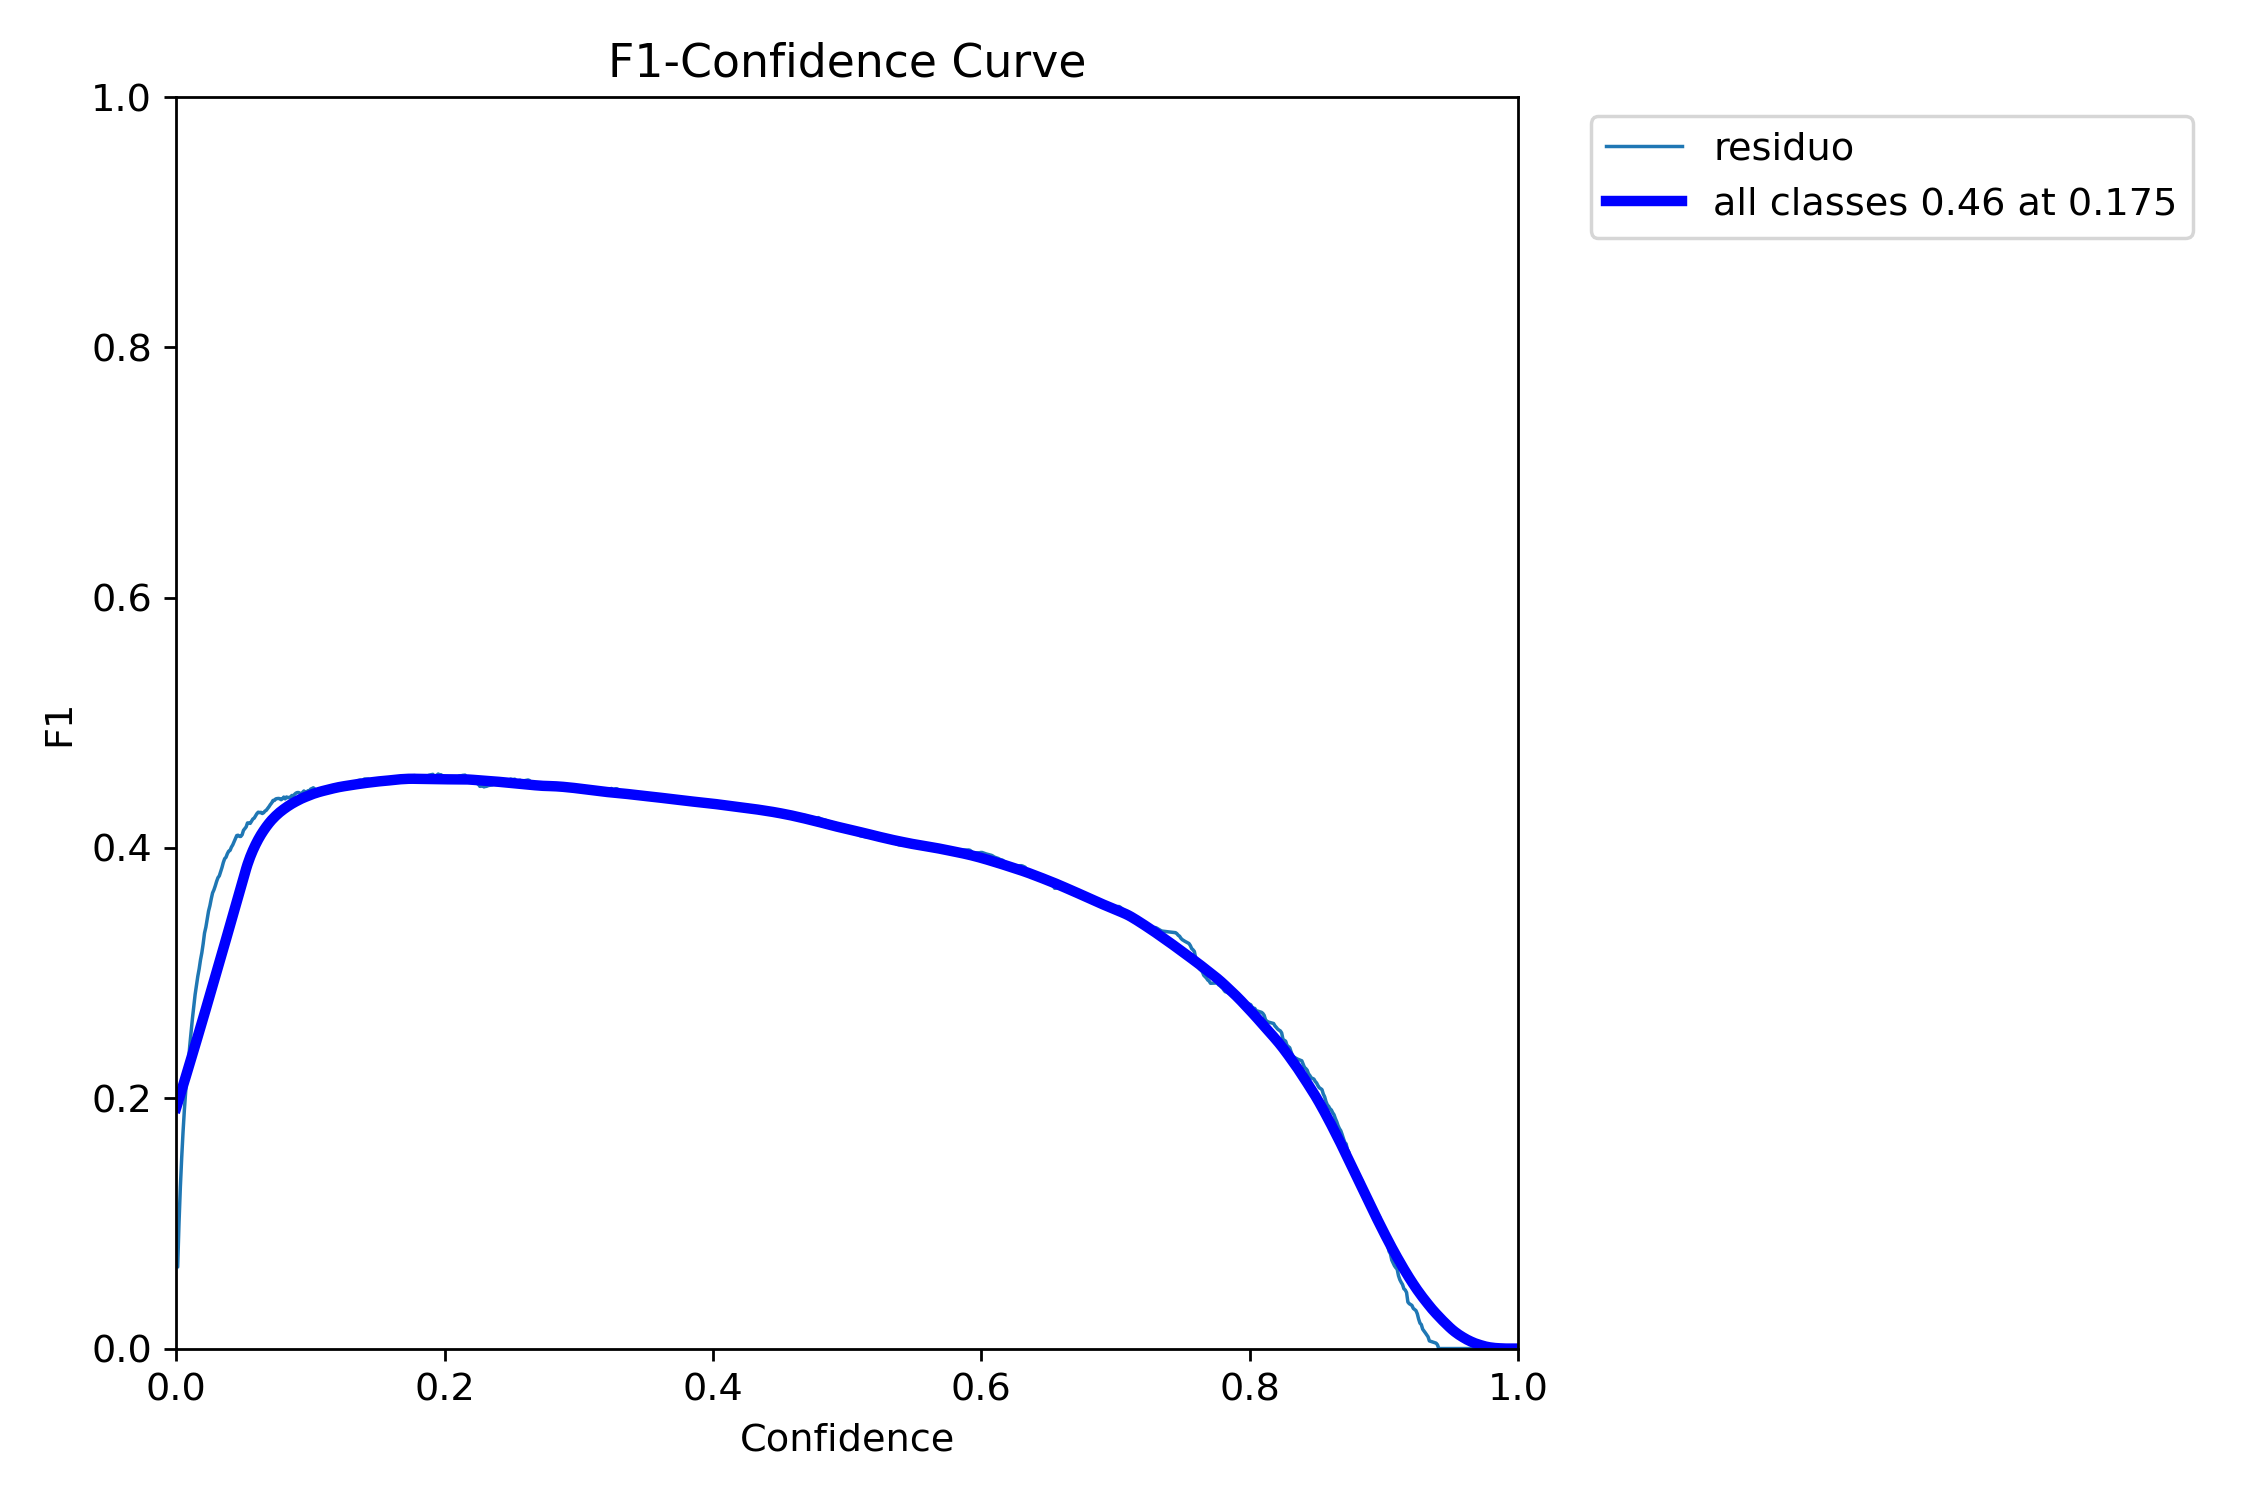

In [ ]:
val_teste = melhor.val(data=DATA_YAML, split='test', imgsz=IMGSZ, conf=0.001, iou=0.6, plots=True,
                       project=f'{BASE}/runs', name='teste', exist_ok=True, verbose=False)
P, R = float(val_teste.box.mp), float(val_teste.box.mr)
metricas_teste = {'precisao': P, 'recall': R, 'f1': 2 * P * R / (P + R + 1e-9),
                  'mAP50': float(val_teste.box.map50), 'mAP50_95': float(val_teste.box.map)}
display(pd.DataFrame([metricas_teste]).round(3))

pasta_teste = str(val_teste.save_dir)
for padrao in ('confusion_matrix*.png', '*PR_curve.png', '*F1_curve.png'):
    for f in sorted(glob.glob(f'{pasta_teste}/{padrao}')):
        display(IPImage(f, width=600)); shutil.copy(f, f'{RES}/teste_{os.path.basename(f)}')

## 7. Escolha do limiar de confiança

O limiar decide a partir de qual confiança uma caixa vira "ocorrência". Varremos limiares de 0,05 a 0,90 no teste, com casamento guloso por IoU ≥ 0,5, e calculamos precisão, recall, F1 e F2.

- O **F1** equilibra precisão e recall, e é o critério padrão adotado (`LIMIAR`).
- O **F2** pesa o recall duas vezes mais. Ele faz sentido para triagem, porque **deixar de ver um ponto de lixo custa mais caro** que um alarme falso, já que um humano confere antes de despachar a equipe. O limiar por F2 é impresso como alternativa.

Também calculamos a **matriz de confusão por imagem** ("precisa de inspeção?" sim/não). Ela só é informativa se houver imagens negativas (ruas limpas) no teste.

,limiar,TP,FP,FN,precisao,recall,f1,f2
0,0.05,445,735,530,0.377,0.456,0.413,0.438
1,0.10,401,405,574,0.498,0.411,0.450,0.426
2,0.15,379,290,596,0.567,0.389,0.461,0.415
3,0.20,361,226,614,0.615,0.370,0.462,0.402
4,0.25,335,178,640,0.653,0.344,0.450,0.380
5,0.30,322,139,653,0.698,0.330,0.448,0.369
6,0.35,312,108,663,0.743,0.320,0.447,0.361
7,0.40,303,91,672,0.769,0.311,0.443,0.353
8,0.45,287,74,688,0.795,0.294,0.430,0.337
9,0.50,271,61,704,0.816,0.278,0.415,0.320


Limiar adotado (máx. F1): 0.2 | alternativa com foco em recall (máx. F2): 0.05


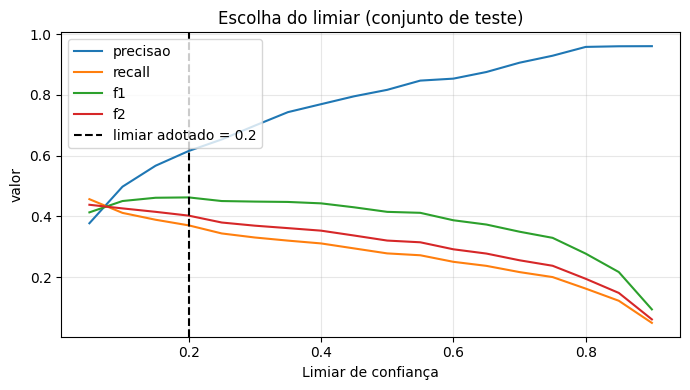

,previsto: com resíduo,previsto: limpa
real: com resíduo,222,3
real: limpa,0,0


Aviso: o teste não tem imagens limpas; a linha "real: limpa" fica vazia. Adicione NEGATIVOS_ZIP para medir falsos alarmes por imagem.


In [ ]:
lista_teste = sorted(glob.glob(f'{YOLO_DIR}/images/test/*.jpg'))

def gt_xyxy(caminho_img, shape):
    h, w = shape
    lab = caminho_img.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'
    caixas = []
    for l in open(lab).read().split('\n'):
        if l.strip():
            _, cx, cy, bw, bh = map(float, l.split())
            caixas.append([(cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h])
    return np.array(caixas).reshape(-1, 4)

def iou_matriz(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = lambda c: (c[:, 2] - c[:, 0]) * (c[:, 3] - c[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)

def casar(pred, conf, gt, limiar, iou_min=0.5):
    # Retorna (vetor TP por predição, vetor 'encontrado' por GT) com casamento guloso por confiança
    ordem = np.argsort(-conf); pred, conf = pred[ordem], conf[ordem]
    sel = conf >= limiar; pred = pred[sel]
    ious = iou_matriz(pred, gt); usado = np.zeros(len(gt), bool); tp = np.zeros(len(pred), bool)
    for i in range(len(pred)):
        if len(gt) == 0:
            break
        cand = np.where(~usado & (ious[i] >= iou_min))[0]
        if len(cand):
            j = cand[np.argmax(ious[i, cand])]; usado[j] = True; tp[i] = True
    return tp, usado

def predizer_lista(fontes, modelo=None, conf=0.01):
    modelo = modelo or melhor; saida = []
    for r in modelo.predict(source=fontes, imgsz=IMGSZ, conf=conf, stream=True, verbose=False):
        saida.append((r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(), r.orig_shape))
    return saida

preds_teste = predizer_lista(lista_teste)
gts_teste = [gt_xyxy(p, sh) for p, (_, _, sh) in zip(lista_teste, preds_teste)]

def avaliar(preds, gts, limiar):
    TP = FP = FN = 0
    for (pb, pc, _), g in zip(preds, gts):
        tp, achou = casar(pb, pc, g, limiar)
        TP += tp.sum(); FP += (~tp).sum(); FN += (~achou).sum()
    p = TP / (TP + FP + 1e-9); r = TP / (TP + FN + 1e-9)
    return {'limiar': round(limiar, 2), 'TP': int(TP), 'FP': int(FP), 'FN': int(FN), 'precisao': p, 'recall': r,
            'f1': 2 * p * r / (p + r + 1e-9), 'f2': 5 * p * r / (4 * p + r + 1e-9)}

varredura = pd.DataFrame([avaliar(preds_teste, gts_teste, t) for t in np.arange(0.05, 0.91, 0.05)])
LIMIAR = float(varredura.loc[varredura.f1.idxmax(), 'limiar'])
LIMIAR_F2 = float(varredura.loc[varredura.f2.idxmax(), 'limiar'])
varredura.round(3).to_csv(f'{RES}/varredura_limiar.csv', index=False)
display(varredura.round(3))
print(f'Limiar adotado (máx. F1): {LIMIAR} | alternativa com foco em recall (máx. F2): {LIMIAR_F2}')

plt.figure(figsize=(7, 4))
for c in ('precisao', 'recall', 'f1', 'f2'):
    plt.plot(varredura.limiar, varredura[c], label=c)
plt.axvline(LIMIAR, color='k', ls='--', label=f'limiar adotado = {LIMIAR}')
plt.xlabel('Limiar de confiança'); plt.ylabel('valor'); plt.legend(); plt.grid(alpha=.3); plt.title('Escolha do limiar (conjunto de teste)')
plt.tight_layout(); plt.savefig(f'{RES}/escolha_limiar.png', dpi=120); plt.show()

# Matriz de confusão por imagem: 'precisa de inspeção?'
y_true = np.array([len(g) > 0 for g in gts_teste]); y_pred = np.array([(pc >= LIMIAR).any() for _, pc, _ in preds_teste])
mc = pd.DataFrame([[np.sum(y_true & y_pred), np.sum(y_true & ~y_pred)], [np.sum(~y_true & y_pred), np.sum(~y_true & ~y_pred)]],
                  index=['real: com resíduo', 'real: limpa'], columns=['previsto: com resíduo', 'previsto: limpa'])
display(mc); mc.to_csv(f'{RES}/matriz_confusao_por_imagem.csv')
if (~y_true).sum() == 0:
    print('Aviso: o teste não tem imagens limpas; a linha "real: limpa" fica vazia. Adicione NEGATIVOS_ZIP para medir falsos alarmes por imagem.')

## 8. Análise de erros e interferências do ambiente urbano

Fazemos três análises complementares:

1. **Recall por condição da imagem e do objeto**, com medidas automáticas:
   - iluminação: brilho médio (escura < 70, normal, clara > 185 em 0 a 255);
   - textura complexa: variância do Laplaciano (alta = muitos detalhes, como folhas, calçada portuguesa ou grama);
   - tamanho do objeto: menos de 1% da imagem = pequeno.
2. **Teste de robustez com perturbações sintéticas** aplicadas às mesmas imagens de teste: escurecimento, superexposição, **sombra** (faixa escurecida sobre a cena) e **obstrução parcial** (retângulo cinza cobrindo 30% de cada objeto). Como a geometria não muda, os rótulos continuam válidos e a queda de desempenho isola o efeito de cada interferência.
3. **Galeria de acertos e erros** (verde = rótulo real, vermelho = previsão) para a análise qualitativa no relatório.

In [ ]:
linhas_erro = []
for caminho, (pb, pc, sh), g in zip(lista_teste, preds_teste, gts_teste):
    if len(g) == 0:
        continue
    cinza = cv2.cvtColor(cv2.imread(caminho), cv2.COLOR_BGR2GRAY)
    brilho = cinza.mean(); textura = cv2.Laplacian(cinza, cv2.CV_64F).var()
    _, achou = casar(pb, pc, g, LIMIAR)
    area_img = sh[0] * sh[1]
    for k, caixa in enumerate(g):
        linhas_erro.append({'imagem': os.path.basename(caminho), 'encontrado': bool(achou[k]), 'brilho': brilho, 'textura': textura,
                            'area_rel': (caixa[2] - caixa[0]) * (caixa[3] - caixa[1]) / area_img})
df_err = pd.DataFrame(linhas_erro)
df_err['iluminacao'] = pd.cut(df_err.brilho, [0, 70, 185, 256], labels=['escura', 'normal', 'clara'])
q = df_err.textura.quantile([0.33, 0.66]).values
df_err['textura_cat'] = pd.cut(df_err.textura, [-1, q[0], q[1], np.inf], labels=['simples', 'média', 'complexa'])
df_err['tamanho'] = pd.cut(df_err.area_rel, [0, 0.01, 0.05, 1.01], labels=['pequeno (<1%)', 'médio (1–5%)', 'grande (>5%)'])

for col in ('iluminacao', 'textura_cat', 'tamanho'):
    t = df_err.groupby(col, observed=True).encontrado.agg(objetos='count', recall='mean').round(3)
    display(t); t.to_csv(f'{RES}/recall_por_{col}.csv')

,objetos,recall
iluminacao,,
escura,61,0.213
normal,914,0.381


,objetos,recall
textura_cat,,
simples,383,0.326
média,274,0.281
complexa,318,0.500


,objetos,recall
tamanho,,
pequeno (<1%),750,0.267
médio (1–5%),138,0.710
grande (>5%),87,0.724


,condicao,precisao,recall,f1,TP,FP,FN
0,original,0.615,0.370,0.462,361,226,614
1,escurecida,0.502,0.361,0.420,352,349,623
2,superexposta,0.619,0.233,0.338,227,140,748
3,sombra,0.478,0.330,0.391,322,352,653
4,obstrucao_30pct,0.562,0.336,0.421,328,256,647


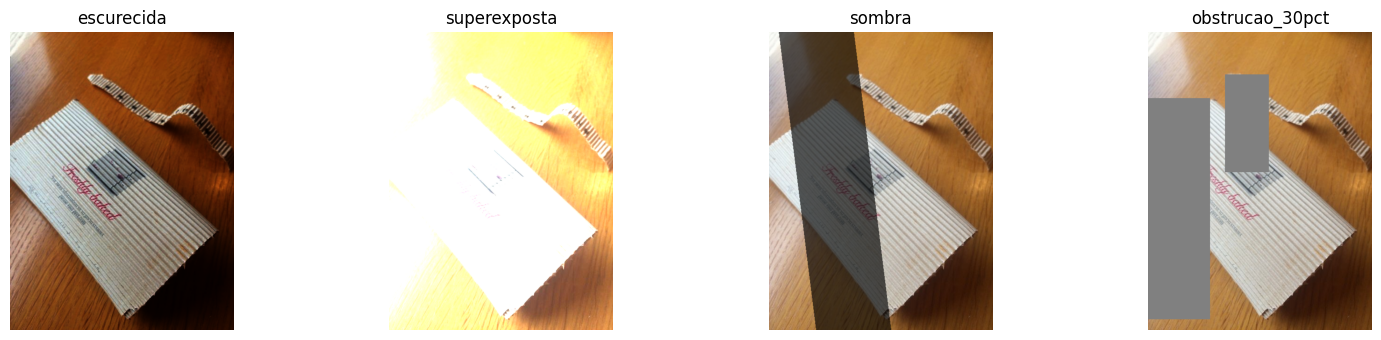

In [ ]:
rng = np.random.default_rng(SEED)
def escurecer(img, g=None):   return np.clip(255 * (img / 255.0) ** 2.2, 0, 255).astype(np.uint8)
def superexpor(img, g=None):  return np.clip(img.astype(np.float32) * 1.8 + 40, 0, 255).astype(np.uint8)
def sombra(img, g=None):
    h, w = img.shape[:2]; mascara = np.zeros((h, w), np.uint8)
    x0 = rng.integers(0, w // 2); pts = np.array([[x0, 0], [x0 + w // 3, 0], [x0 + w // 2, h], [x0 + w // 6, h]])
    cv2.fillPoly(mascara, [pts], 1); saida = img.astype(np.float32); saida[mascara == 1] *= 0.35
    return saida.astype(np.uint8)
def obstruir(img, g):
    saida = img.copy()
    h, w = img.shape[:2]
    for x1, y1, x2, y2 in np.clip(g, 0, [w, h, w, h]).astype(int):   # cobre 30% da largura de cada objeto (poste, pessoa, carro)
        larg = max(1, int(0.3 * (x2 - x1))); saida[y1:y2, x1:x1 + larg] = 128
    return saida

perturbacoes = {'original': None, 'escurecida': escurecer, 'superexposta': superexpor, 'sombra': sombra, 'obstrucao_30pct': obstruir}
robustez = []; exemplos_pert = {}
for nome, fn in perturbacoes.items():
    if fn is None:
        pr = preds_teste
    else:
        imgs = [fn(cv2.imread(p), g) for p, g in zip(lista_teste, gts_teste)]
        exemplos_pert[nome] = imgs[0]; pr = predizer_lista(imgs)
    r = avaliar(pr, gts_teste, LIMIAR); r['condicao'] = nome; robustez.append(r)
df_rob = pd.DataFrame(robustez)[['condicao', 'precisao', 'recall', 'f1', 'TP', 'FP', 'FN']].round(3)
df_rob.to_csv(f'{RES}/robustez_interferencias.csv', index=False); display(df_rob)

fig, ax = plt.subplots(1, len(exemplos_pert), figsize=(4 * len(exemplos_pert), 3.5))
for a, (nome, im) in zip(np.atleast_1d(ax), exemplos_pert.items()):
    a.imshow(im[..., ::-1]); a.set_title(nome); a.axis('off')
plt.tight_layout(); plt.savefig(f'{RES}/exemplos_perturbacoes.png', dpi=100); plt.show()

In [ ]:
def painel(caminho, pb, pc, g):
    img = cv2.imread(caminho)
    for c in g.astype(int):
        cv2.rectangle(img, (int(c[0]), int(c[1])), (int(c[2]), int(c[3])), (0, 200, 0), 3)
    for c, s in zip(pb.astype(int), pc):
        if s >= LIMIAR:
            cv2.rectangle(img, (int(c[0]), int(c[1])), (int(c[2]), int(c[3])), (0, 0, 255), 2)
            cv2.putText(img, f'{s:.2f}', (int(c[0]), int(max(15, c[1] - 5))), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
    return img[..., ::-1]

resumo_img = []
for caminho, (pb, pc, sh), g in zip(lista_teste, preds_teste, gts_teste):
    tp, achou = casar(pb, pc, g, LIMIAR)
    resumo_img.append({'caminho': caminho, 'FP': int((~tp).sum()), 'FN': int((~achou).sum()), 'TP': int(tp.sum())})
df_img = pd.DataFrame(resumo_img)

grupos_gal = {'Acertos (TP, sem erros)': df_img[(df_img.FP == 0) & (df_img.FN == 0) & (df_img.TP > 0)].head(4),
              'Mais resíduos NÃO detectados (FN)': df_img.sort_values('FN', ascending=False).head(4),
              'Mais alarmes falsos (FP)': df_img.sort_values('FP', ascending=False).head(4)}
for titulo, sub in grupos_gal.items():
    if len(sub) == 0:
        continue
    fig, ax = plt.subplots(1, len(sub), figsize=(4.5 * len(sub), 4))
    for a, (_, linha) in zip(np.atleast_1d(ax), sub.iterrows()):
        k = lista_teste.index(linha.caminho); pb, pc, _ = preds_teste[k]
        a.imshow(painel(linha.caminho, pb, pc, gts_teste[k])); a.set_title(f'TP={linha.TP} FP={linha.FP} FN={linha.FN}'); a.axis('off')
    plt.suptitle(titulo + '  (verde = rótulo real, vermelho = previsão)'); plt.tight_layout()
    arq = {'Acertos': 'acertos', 'Mais resíduos': 'falsos_negativos', 'Mais alarmes': 'falsos_positivos'}
    nome_arq = next(v for k, v in arq.items() if titulo.startswith(k))
    plt.savefig(f'{RES}/galeria_{nome_arq}.png', dpi=100); plt.show()

**Análise qualitativa (preencher após ver as galerias):** para cada erro relevante, anote a causa provável no dicionário abaixo. Use as categorias do enunciado (sombra, iluminação, textura complexa, obstrução parcial) ou outras que aparecerem, como objeto pequeno, rótulo ausente na base ou lixo confundido com folhas. A tabela gerada vai direto para o relatório.

In [ ]:
CAUSAS_MANUAIS = {
    # 'nome_da_imagem.jpg': 'sombra',
}
if CAUSAS_MANUAIS:
    t = pd.Series(CAUSAS_MANUAIS).value_counts().rename('ocorrências'); display(t); t.to_csv(f'{RES}/causas_erros_manuais.csv')

## 9. Integração ao CitizenTech: função de análise e pacote de triagem

`analisar_imagem()` é o ponto de integração com o protótipo. Ela recebe uma imagem (foto do cidadão ou quadro de câmera) e devolve:
- a **imagem anotada**, com caixas e a confiança de cada uma;
- um **JSON de triagem** para o back-end do Radar Cidadão: ocorrências, confiança, área ocupada, `precisa_inspecao`, prioridade e latência.

A prioridade é uma regra simples e explicável: **alta** se alguma detecção tem confiança ≥ 0,75 e os resíduos ocupam ≥ 5% da imagem; **média** se há qualquer detecção acima do limiar. O pacote sempre leva o aviso de que a detecção não substitui a vistoria.

In [ ]:
def analisar_imagem(img_rgb, limiar=None, modelo=None):
    limiar = LIMIAR if limiar is None else float(limiar); modelo = modelo or melhor
    bgr = np.ascontiguousarray(img_rgb[..., ::-1])
    t0 = time.perf_counter()
    r = modelo.predict(bgr, imgsz=IMGSZ, conf=limiar, verbose=False)[0]
    latencia = (time.perf_counter() - t0) * 1000
    h, w = r.orig_shape
    caixas, confs = r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()
    ocorr = [{'tipo': CLASSE_PT, 'confianca': round(float(c), 3), 'bbox_xyxy_px': [int(v) for v in b]} for b, c in zip(caixas, confs)]
    area = float(sum((b[2] - b[0]) * (b[3] - b[1]) for b in caixas) / (h * w)) if len(caixas) else 0.0
    if len(ocorr) and confs.max() >= 0.75 and area >= 0.05:
        prioridade = 'alta'
    elif len(ocorr):
        prioridade = 'media'
    else:
        prioridade = 'nenhuma'
    pacote = {'app': 'Radar Cidadão', 'modulo': 'visao_computacional', 'limiar_confianca': limiar,
              'precisa_inspecao': bool(len(ocorr)), 'prioridade_triagem': prioridade, 'n_ocorrencias': len(ocorr),
              'confianca_maxima': round(float(confs.max()), 3) if len(confs) else 0.0, 'area_ocupada_pct': round(100 * area, 1),
              'ocorrencias': ocorr, 'latencia_ms': round(latencia, 1), 'resolucao_entrada': f'{w}x{h}',
              'relacao_alagamento': 'Resíduo em via pública pode entupir bocas de lobo e agravar alagamentos.' if len(ocorr) else None,
              'aviso': 'Triagem automática. Não substitui a vistoria técnica presencial.'}
    return r.plot()[..., ::-1], pacote

# Teste com uma imagem estática do conjunto de teste
img = cv2.imread(lista_teste[0])[..., ::-1]
anotada, pacote = analisar_imagem(img)
plt.figure(figsize=(8, 6)); plt.imshow(anotada); plt.axis('off'); plt.title('Saída do módulo'); plt.show()
print(json.dumps(pacote, ensure_ascii=False, indent=2))

## 10. Monitoramento contínuo: sequência de quadros e vídeo

Para simular uma câmera de monitoramento, montamos um **vídeo a partir das imagens de teste** (2 quadros/s, 960×720). A função `processar_video()` também aceita qualquer vídeo real gravado pelo grupo (por exemplo, andando por uma rua). Ela analisa 1 a cada N quadros, grava o vídeo anotado, mede o FPS de processamento e gera um registro temporal das ocorrências.

In [ ]:
def letterbox(img, W=960, H=720):
    h, w = img.shape[:2]; s = min(W / w, H / h); img = cv2.resize(img, (int(w * s), int(h * s)))
    tela = np.full((H, W, 3), 114, np.uint8); y0, x0 = (H - img.shape[0]) // 2, (W - img.shape[1]) // 2
    tela[y0:y0 + img.shape[0], x0:x0 + img.shape[1]] = img; return tela

VIDEO_SIM = f'{BASE}/camera_simulada.mp4'
wr = cv2.VideoWriter(VIDEO_SIM, cv2.VideoWriter_fourcc(*'mp4v'), 2, (960, 720))
for p in lista_teste[:60]:
    wr.write(letterbox(cv2.imread(p)))
wr.release()

def processar_video(caminho, passo=1, limiar=None, saida=f'{BASE}/video_anotado.mp4'):
    limiar = LIMIAR if limiar is None else float(limiar)
    cap = cv2.VideoCapture(caminho); fps_in = cap.get(cv2.CAP_PROP_FPS) or 10
    W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    tmp = saida.replace('.mp4', '_tmp.mp4')
    wr = cv2.VideoWriter(tmp, cv2.VideoWriter_fourcc(*'mp4v'), max(fps_in / passo, 1), (W, H))
    registro, tempos, i = [], [], 0
    t_total = time.perf_counter()
    while True:
        ok, quadro = cap.read()
        if not ok:
            break
        if i % passo == 0:
            t0 = time.perf_counter(); r = melhor.predict(quadro, imgsz=IMGSZ, conf=limiar, verbose=False)[0]; tempos.append(time.perf_counter() - t0)
            wr.write(r.plot()); confs = r.boxes.conf.cpu().numpy()
            registro.append({'quadro': i, 'tempo_video_s': round(i / fps_in, 2), 'ocorrencias': len(confs),
                             'confianca_max': round(float(confs.max()), 3) if len(confs) else 0.0})
        i += 1
    t_total = time.perf_counter() - t_total
    cap.release(); wr.release()
    subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', tmp, '-vcodec', 'libx264', '-pix_fmt', 'yuv420p', saida])
    resumo = {'quadros_lidos': i, 'quadros_analisados': len(tempos), 'resolucao': f'{W}x{H}', 'imgsz_modelo': IMGSZ,
              'latencia_media_ms': round(1000 * np.mean(tempos), 1) if tempos else None,
              'fps_inferencia': round(len(tempos) / sum(tempos), 1) if tempos else None,
              'fps_ponta_a_ponta': round(len(tempos) / t_total, 1) if tempos else None,
              'quadros_com_ocorrencia': int(sum(r['ocorrencias'] > 0 for r in registro))}
    return saida, resumo, pd.DataFrame(registro)

saida_vid, resumo_vid, registro_vid = processar_video(VIDEO_SIM)
print(json.dumps(resumo_vid, ensure_ascii=False, indent=2)); display(registro_vid.head(10))
registro_vid.to_csv(f'{RES}/registro_monitoramento.csv', index=False)
json.dump(resumo_vid, open(f'{RES}/resumo_video.json', 'w'), ensure_ascii=False, indent=2)

plt.figure(figsize=(9, 2.8)); plt.step(registro_vid.tempo_video_s, registro_vid.ocorrencias, where='post')
plt.xlabel('tempo do vídeo (s)'); plt.ylabel('ocorrências'); plt.title('Linha do tempo do monitoramento'); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f'{RES}/linha_tempo_monitoramento.png', dpi=120); plt.show()

### Interface do protótipo (Gradio)

A célula abaixo sobe a tela do módulo dentro do Radar Cidadão, com um link público temporário (`share=True`). Ela tem duas abas:
- **Foto do cidadão:** envio de uma imagem, ajuste do limiar e resultado com caixas, confiança e o JSON de triagem;
- **Monitoramento contínuo:** envio de um vídeo e retorno do vídeo anotado, do FPS medido e da linha do tempo.

Use esta tela para gravar o vídeo de demonstração.

In [ ]:
import gradio as gr

def ui_imagem(img, limiar):
    if img is None:
        return None, {'erro': 'Envie uma imagem.'}
    return analisar_imagem(img, limiar)

def ui_video(caminho, passo, limiar):
    if not caminho:
        return None, {'erro': 'Envie um vídeo.'}, None
    return processar_video(caminho, int(passo), limiar)

with gr.Blocks(title='Radar Cidadão — Visão Computacional') as demo:
    gr.Markdown('# Radar Cidadão — Detecção de lixo e entulho em via pública\n'
                'Triagem automática para priorizar inspeções. **Não substitui a vistoria técnica presencial.**')
    with gr.Tab('Foto do cidadão'):
        with gr.Row():
            ent = gr.Image(type='numpy', label='Foto da ocorrência')
            sai = gr.Image(label='Resultado (caixas + confiança)')
        lim = gr.Slider(0.05, 0.95, value=LIMIAR, step=0.05, label='Limiar de confiança')
        btn = gr.Button('Analisar', variant='primary')
        js = gr.JSON(label='Pacote de triagem enviado ao Radar Cidadão')
        btn.click(ui_imagem, [ent, lim], [sai, js])
        gr.Examples([[p] for p in lista_teste[:6]], inputs=[ent])
    with gr.Tab('Monitoramento contínuo (vídeo)'):
        vid = gr.Video(label='Vídeo de câmera ou gravado na rua')
        with gr.Row():
            passo = gr.Slider(1, 15, value=1, step=1, label='Analisar 1 a cada N quadros')
            lim2 = gr.Slider(0.05, 0.95, value=LIMIAR, step=0.05, label='Limiar de confiança')
        btn2 = gr.Button('Processar sequência', variant='primary')
        vout = gr.Video(label='Vídeo anotado'); resumo = gr.JSON(label='Desempenho (latência e FPS)')
        tabela = gr.Dataframe(label='Linha do tempo das ocorrências')
        btn2.click(ui_video, [vid, passo, lim2], [vout, resumo, tabela])
        gr.Examples([[VIDEO_SIM]], inputs=[vid])

demo.launch(share=True, debug=False)

/usr/local/lib/python3.13/dist-packages/gradio/components/video.py:469: UserWarning: Video does not have browser-compatible container or codec. Converting to mp4.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/gradio/components/video.py:469: UserWarning: Video does not have browser-compatible container or codec. Converting to mp4.
  warnings.warn(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://44b37d9e9c8bafe386.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 11. Desempenho computacional: latência e FPS

Medimos com 10 inferências de aquecimento, seguidas de 100 medições na GPU ou 30 na CPU, sobre imagens reais de teste. Registramos:
- a **latência total** por imagem (média, p50, p95) e o **FPS** correspondente;
- a divisão do tempo em pré-processamento, inferência e pós-processamento (NMS), informada pelo Ultralytics;
- várias configurações: GPU em FP32 e FP16, CPU, entradas de 640 e 320 px.

Também medimos o **mAP com entrada de 320 px**, para mostrar o equilíbrio entre qualidade e velocidade.

In [ ]:
def info_hardware():
    cpu = next((l.split(':', 1)[1].strip() for l in open('/proc/cpuinfo') if 'model name' in l), platform.processor())
    ram = next((int(l.split()[1]) / 1e6 for l in open('/proc/meminfo') if l.startswith('MemTotal')), None)
    return {'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'nenhuma', 'cpu': cpu,
            'nucleos_cpu': os.cpu_count(), 'ram_gb': round(ram, 1) if ram else None,
            'torch': torch.__version__, 'ultralytics': ultralytics.__version__, 'cuda': torch.version.cuda}

def benchmark(dispositivo, imgsz, half=False, n=100):
    m = YOLO(PESOS); imgs = [cv2.imread(p) for p in lista_teste[:20]]
    for k in range(10):
        m.predict(imgs[k % len(imgs)], imgsz=imgsz, device=dispositivo, half=half, verbose=False)
    tot, pre, inf, pos = [], [], [], []
    for k in range(n):
        if dispositivo != 'cpu': torch.cuda.synchronize()
        t0 = time.perf_counter()
        r = m.predict(imgs[k % len(imgs)], imgsz=imgsz, device=dispositivo, half=half, verbose=False)[0]
        if dispositivo != 'cpu': torch.cuda.synchronize()
        tot.append((time.perf_counter() - t0) * 1000)
        pre.append(r.speed['preprocess']); inf.append(r.speed['inference']); pos.append(r.speed['postprocess'])
    return {'dispositivo': 'GPU' if dispositivo != 'cpu' else 'CPU', 'precisao_num': 'FP16' if half else 'FP32', 'imgsz': imgsz,
            'lat_media_ms': np.mean(tot), 'lat_p50_ms': np.percentile(tot, 50), 'lat_p95_ms': np.percentile(tot, 95),
            'fps': 1000 / np.mean(tot), 'pre_ms': np.mean(pre), 'inferencia_ms': np.mean(inf), 'pos_nms_ms': np.mean(pos)}

hw = info_hardware(); print(json.dumps(hw, ensure_ascii=False, indent=2))
dims_teste = np.array([Image.open(p).size for p in lista_teste])
print(f'Resolução média das imagens de entrada (teste): {dims_teste[:,0].mean():.0f}x{dims_teste[:,1].mean():.0f} px → redimensionadas pelo modelo para imgsz')

configs = []
if torch.cuda.is_available():
    configs += [(0, 640, False, 100), (0, 640, True, 100), (0, 320, False, 100)]
configs += [('cpu', 640, False, 30), ('cpu', 320, False, 30)]
df_bench = pd.DataFrame([benchmark(*c) for c in configs]).round(2)
display(df_bench); df_bench.to_csv(f'{RES}/benchmark_latencia_fps.csv', index=False)

# Qualidade x velocidade: mAP com entrada de 320 px
v320 = melhor.val(data=DATA_YAML, split='test', imgsz=320, conf=0.001, iou=0.6, plots=False, verbose=False,
                  project=f'{BASE}/runs', name='teste320', exist_ok=True)
qv = pd.DataFrame([{'imgsz': 640, 'mAP50': metricas_teste['mAP50'], 'mAP50_95': metricas_teste['mAP50_95']},
                   {'imgsz': 320, 'mAP50': float(v320.box.map50), 'mAP50_95': float(v320.box.map)}]).round(3)
display(qv); qv.to_csv(f'{RES}/qualidade_vs_resolucao.csv', index=False)

if PESOS_COMP:   # comparação opcional de arquitetura
    m_s = YOLO(PESOS_COMP); vs = m_s.val(data=DATA_YAML, split='test', imgsz=IMGSZ, conf=0.001, iou=0.6, plots=False, verbose=False,
                                         project=f'{BASE}/runs', name='teste_s', exist_ok=True)
    PESOS_ORIG = PESOS; PESOS = PESOS_COMP
    b_s = benchmark(0 if torch.cuda.is_available() else 'cpu', IMGSZ, n=50); PESOS = PESOS_ORIG
    comp = pd.DataFrame([{'modelo': 'yolo11n', 'mAP50': metricas_teste['mAP50'], 'fps': df_bench.iloc[0].fps},
                         {'modelo': 'yolo11s', 'mAP50': float(vs.box.map50), 'fps': b_s['fps']}]).round(3)
    display(comp); comp.to_csv(f'{RES}/comparacao_arquiteturas.csv', index=False)

## 12. Exportação dos resultados para o relatório técnico

Gera `radar_cidadao_resultados.zip` com todas as tabelas (CSV), gráficos (PNG), o resumo em JSON e os pesos do modelo (`best.pt`).

**Pontos para discutir no relatório** (use os números reais gerados acima):
- **Métricas:** precisão, recall, F1, mAP@0,5 e mAP@0,5:0,95 no teste (seção 6), mais a matriz de confusão.
- **Limiar:** valor adotado e a curva da seção 7, explicando a troca entre alarmes falsos e ocorrências perdidas.
- **Erros:** recall por iluminação, textura e tamanho, a tabela de robustez e as galerias (seção 8).
- **Desempenho:** latência e FPS por configuração, com o hardware exato (seção 11), e se o FPS atende o monitoramento contínuo.
- **Limites da base:** a TACO tem muitas fotos de perto de itens isolados e poucas de grandes pontos de descarte ou entulho em ruas brasileiras. Isso é uma **diferença de domínio**. A melhoria recomendada é acrescentar uma amostra rotulada de fotos de São Paulo (`FONTE_DADOS='proprio'`) e de ruas limpas (`NEGATIVOS_ZIP`).
- **Uso responsável:** a detecção prioriza a fila de inspeções, mas a gravidade só é confirmada na vistoria presencial. Fotos com pessoas ou placas devem ter rostos e placas borrados antes de qualquer armazenamento (LGPD).

In [ ]:
resumo_final = {'app': 'Radar Cidadão', 'nicho': CLASSE_PT, 'fonte_dados': FONTE_DADOS, 'modelo_base': MODELO_BASE,
                'imgsz': IMGSZ, 'epocas_max': EPOCAS, 'limiar_adotado': LIMIAR, 'limiar_alternativo_f2': LIMIAR_F2,
                'divisao': tab_split.to_dict('records'), 'metricas_teste': {k: round(v, 4) for k, v in metricas_teste.items()},
                'robustez': df_rob.to_dict('records'), 'monitoramento_video': resumo_vid, 'hardware': hw,
                'benchmark': df_bench.to_dict('records'), 'qualidade_vs_resolucao': qv.to_dict('records')}
json.dump(resumo_final, open(f'{RES}/resumo_final.json', 'w'), ensure_ascii=False, indent=2, default=float)
shutil.copy(PESOS, f'{RES}/best.pt')
shutil.make_archive('/content/radar_cidadao_resultados', 'zip', RES)
print(json.dumps(resumo_final['metricas_teste'], indent=2))
try:
    from google.colab import files; files.download('/content/radar_cidadao_resultados.zip')
except Exception:
    print('Arquivo gerado em /content/radar_cidadao_resultados.zip')

{
  "precisao": 0.6042,
  "recall": 0.3672,
  "f1": 0.4568,
  "mAP50": 0.4003,
  "mAP50_95": 0.2538
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Teste com fotos reais de rua (fora da TACO)

Duas fotos de ruas brasileiras com lixo acumulado, que não fazem parte da base, passam pela mesma função analisar_imagem() usada no protótipo, com o limiar adotado (máx. F1) e com o limiar alternativo (máx. F2). O teste mostra na prática a diferença de domínio discutida na seção 12: montes de sacos e entulho na calçada e no meio-fio, em vez dos itens isolados e fotografados de perto que predominam na TACO.

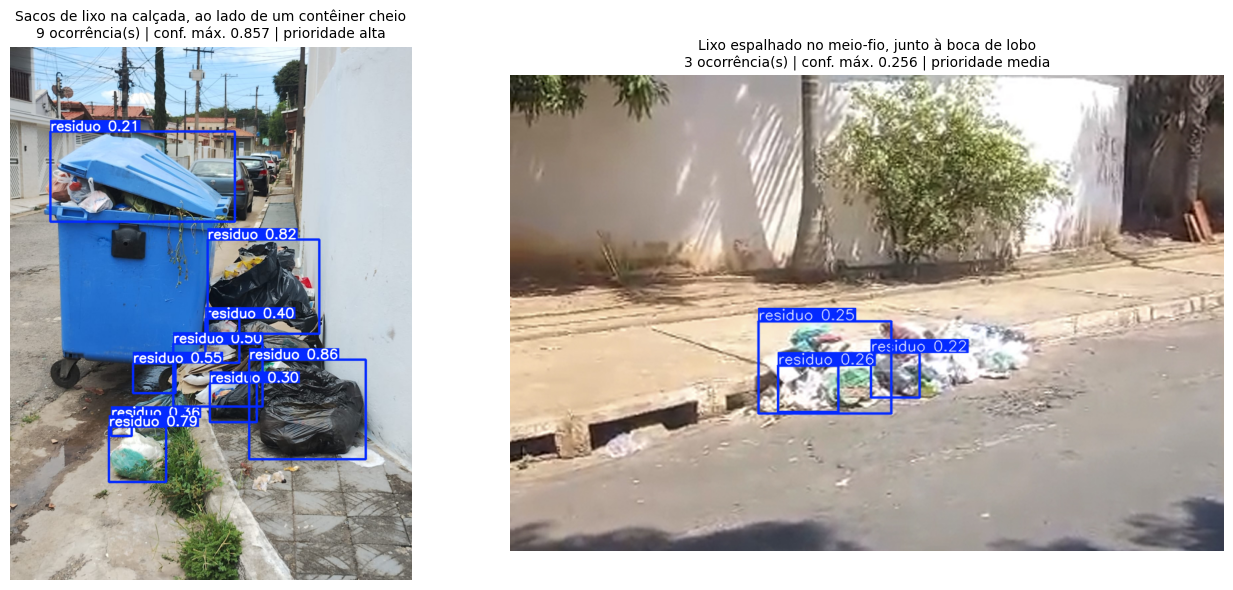

,foto,limiar,ocorrencias,confianca_max,area_ocupada_pct,prioridade,latencia_ms
0,foto_calcada.jpg,0.20,9,0.857,24.5,alta,61.4
1,foto_calcada.jpg,0.05,33,0.857,73.4,alta,25.3
2,foto_meiofio.jpg,0.20,3,0.256,5.1,media,50.7
3,foto_meiofio.jpg,0.05,11,0.256,11.8,media,32.6


In [ ]:
# Fotos reais de rua enviadas pelo grupo (fora da TACO). Envie os arquivos para /content antes de rodar.
FOTOS_REAIS = {'foto_calcada.jpg': 'Sacos de lixo na calçada, ao lado de um contêiner cheio',
               'foto_meiofio.jpg': 'Lixo espalhado no meio-fio, junto à boca de lobo'}
fotos = {k: v for k, v in FOTOS_REAIS.items() if os.path.exists(f'/content/{k}')}
linhas_reais = []
if fotos:
    fig, ax = plt.subplots(1, len(fotos), figsize=(7 * len(fotos), 6))
    for a, (arq, desc) in zip(np.atleast_1d(ax), fotos.items()):
        img = np.array(ImageOps.exif_transpose(Image.open(f'/content/{arq}')).convert('RGB'))
        for lim in (LIMIAR, LIMIAR_F2):
            _, pac = analisar_imagem(img, lim)
            linhas_reais.append({'foto': arq, 'limiar': lim, 'ocorrencias': pac['n_ocorrencias'],
                                 'confianca_max': pac['confianca_maxima'], 'area_ocupada_pct': pac['area_ocupada_pct'],
                                 'prioridade': pac['prioridade_triagem'], 'latencia_ms': pac['latencia_ms']})
        anotada, pac = analisar_imagem(img)
        a.imshow(anotada); a.axis('off')
        a.set_title(f"{desc}\n{pac['n_ocorrencias']} ocorrência(s) | conf. máx. {pac['confianca_maxima']} | prioridade {pac['prioridade_triagem']}", fontsize=10)
    plt.tight_layout(); plt.savefig(f'{RES}/fotos_reais.png', dpi=110); plt.show()
    df_reais = pd.DataFrame(linhas_reais); df_reais.to_csv(f'{RES}/fotos_reais.csv', index=False); display(df_reais)
else:
    print('Nenhuma foto real encontrada em /content; envie foto_calcada.jpg e foto_meiofio.jpg para rodar esta seção.')